# DeviceLayout.jl DemoQPU17 — a 17-qubit surface-code demo (Quantcore PDK rebuild)

**What the chip is.** DeviceLayout.jl's `examples/DemoQPU17` (`DemoQPU17.jl`, `params.jl`, `routing.jl`) with its
`ExamplePDK` components (`ExampleStarTransmon`, `ExampleFilteredHairpinReadout`, `ExampleSeriesClawCapacitor`,
`ExampleChip`), © Amazon.com, Inc. or its affiliates, MIT licence, <https://github.com/aws-cqc/DeviceLayout.jl>. A
depth-1 clone was read on 2026-11-03 in `build/external/DeviceLayout.jl` (read only; the Julia code was never run);
the rendered figure is <https://aws-cqc.github.io/DeviceLayout.jl/stable/examples/qpu17/>. Spec:
`docs/designs/devicelayout/demoqpu17.md`. We distribute the rebuild under GPL-3.0.

It is a demo after the ETH Zurich surface-17 device (Krinner *et al.*, Nature 605, 669 (2022); rebuilt in
`metal/m53_wallraff_17q`):
- 17 star transmons on a 5 × 5 grid at 1.65 mm pitch: 9 data and 8 auxiliary qubits in a checkerboard;
- 24 fixed CPW couplers between nearest neighbours;
- per qubit, a λ/4 hairpin readout resonator with its own λ/4 hairpin Purcell filter, claw-coupled to one of four
  feedlines; each feedline has a series claw input capacitor;
- an XY line and a Z line per qubit, airbridges at every crossing;
- a 15 × 15 mm chip with 48 ports on a 1 mm pitch; ground-plane holes everywhere (`autofill!`).

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`). The
geometry comes from the surface-17 generator `examples/designs/devicelayout/_surface17.py`, which the ETH rebuild
`metal/m53_wallraff_17q` uses too; tutorial 03 shows both chips. Here the chip is built and checked one stage at a
time.

| | DeviceLayout DemoQPU17 | Quantcore PDK rebuild |
|---|---|---|
| chip | `ExampleChip` 15 × 15 mm, centred on (0, 0) | the 15 × 15 mm die with the QCT frame and device ID `QPU17` (Designer = DeviceLayout + (7500, 7500) µm) |
| substrate | the `ExamplePDK` stack (silicon) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| qubits | `ExampleStarTransmon` (a wedge star), no frequencies given | `metal:StarQubit` (5 pads) with a **Quantcore trilayer SQUID**, sized for a plan inside the PDK band |
| readout | `ExampleFilteredHairpinReadout`: readout and Purcell hairpins, a tap capacitor, a claw to the feedline | the same topology from our components: two λ/4 hairpin routes, a declared tap, a `metal:CapNInterdigitalTee` claw stand-in |
| input capacitor | `ExampleSeriesClawCapacitor` (input length 700 µm) | a KQC `FingerCapacitorSquare` 700 µm from each input pad |
| pads | 48 ports, the pad etch 200 µm from the die edge | a `BondPad` on each of the 42 used ports, moved to **100 µm** (`frame.pad_edge`) from its edge (`edge="auto"`) |
| crossings | `crossovers!` airbridges at every crossing | `AirbridgeConnection`s at every crossing of the drawn lines (the generator) |
| cheese | **yes**: `autofill!` with ground holes, radius 5 µm on a 100 µm grid, a 50 µm halo round all geometry, none within 600 µm of the chip edge | **the original's**: the same field as the chip's `cheese` rule, drawn by the build (10 µm squares for the 10 µm circles) |
| placement | centred | centred (no shift needed) |

**Kept from the source:** the active sites and the data / auxiliary roles; the mirroring `MIRRORED_LR` /
`MIRRORED_UD`, which turns every readout diagonal and every XY / Z line away from the lattice centre; the 24
couplers; the readout targets (6.8–7.6 GHz, `params.jl`) and the four feedline groups in DeviceLayout's order; the
port map (`LINE_SPECIFICATIONS`; the 6 unused ports are not drawn); the CPW styles (couplers and resonators 10/10 µm,
feedlines and control lines 10/6 µm); the ground-hole fill.

**Ours (the generator):** the StarQubit size, the diagonal hairpin readout and Purcell modules, the tee taps, the
input capacitors, the control-line fan-out and the airbridges at the crossings; the centre qubit Q33's
closed-plaquette module (its tee in the channel west of the plaquette, the filter lead bridged over the coupler).

**Simplified:** the readout–filter tap is a declared capacitance (`d.couple`, 1.2 fF ≈ J/2π 12 MHz), not drawn; the
feedline meanders that put each tap at a feedline half-wave are not drawn (the LOM lumps the feedline anyway); no
line bridges (`add_bridges!`); the XY / Z lines are 10/6 µm all the way (DeviceLayout tapers them to 3.3/2 µm near the
qubit) and are not drive / flux controls in the LOM; the qubit is Metal's `StarQubit`, not the wedge star.

**Assumed:** DeviceLayout gives no qubit frequencies. The plan puts the data qubits at 4.80–5.20 GHz and the
auxiliaries at 5.80–6.15 GHz, inside the PDK's 4–8 GHz; the junctions are sized on the StarQubit's LOM C_Σ (89 fF) and
the λ/4 lengths carry a loading factor calibrated once with the LOM (Plan 2).

**How this notebook goes.** First the **plan** (what the source fixes, our floorplan, the junctions sized for our qubit plan). Then
the **Design**: the chip is laid out from the plan one segment at a time, each segment its own cell with a picture of
the chip so far — the die, the 42 bond pads, the readout line (17 tees, 4 input capacitors and the four feedlines), the
17 StarQubits, their readout and Purcell λ/4s, the 24 couplers, the 34 Z / XY lines, and then the whole chip. From the
v1 run: ≈ 2.5 min headless (`QCC_LIVE=0`) up to the FEM export; the feedback cells (Results 4–5) add minutes. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `demoqpu17.v1.ipynb`; both save the same
`demoqpu17.json`.

## Setup

The imports, the output folder, `sizing_md` (the junction table of the plan) and the FEM switches. `LIVE`: with KLayout
open (the default) every change below is pushed to the KLayout window as you run it; with `QCC_LIVE=0` the notebook
builds headless and only writes files. `_common` holds the helpers the design notebooks share (tables, snapshots, the
PDK placement, the FEM and feedback steps); `_surface17` is the surface-17 generator.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "devicelayout"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
import _surface17 as S17                         # the surface-17 generator (shared with metal/m53_wallraff_17q)
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/devicelayout")      # this notebook's design JSON and PNG snapshots


def sizing_md(sizing):
    """Trilayer SQUID sizing (``circuit.bridges.size_junction``, n = 2) against the PDK junction rule (as drawn)."""
    rows = ["| qubit | role | f_q plan (GHz) | C_Σ (fF) | L_J (nH) | R_n per junction (kΩ) | device R_n (kΩ) | "
            "drawn f_q (GHz) | R_n in 40–50 kΩ |", "|---|---|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {'data' if name in DATA else 'aux'} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.0f} | "
                    f"{s.drawn.lj_nH:.2f} | {s.drawn.rn_each_kohm:.1f} | {s.drawn.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.drawn.rn_in_window else 'no'} |")
    return "\n".join(rows)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that
means: the 15 mm die gets the QCT frame; the 42 bond pads go `frame.pad_edge` (100 µm) from their edges; each
StarQubit gets a trilayer SQUID; the qubit plan sits inside the PDK's 4–8 GHz band, but the SQUIDs that reach it are
not all inside the R_n window (flagged in Check 1, not retuned); the cheese is the original's (DeviceLayout's
ground-hole fill), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))
print("pad rule: outer etch", get_pdk().frame.pad_edge, "µm from the die edge")

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

pad rule: outer etch 100.0 µm from the die edge


# Plan: what the source fixes, the floorplan, the junctions

The surface-17 generator lays the whole chip out on paper first (`S17.plan_chip`): every instance, every line's
polyline, every crossing with its airbridge. The Design segments below then place it on the chip one kind at a time.

## Plan 1 · What the source fixes: the lattice, the port map, the readout targets, the feedline groups

- **The lattice.** 17 qubits on the 5 × 5 sites `01100 / 01111 / 11111 / 11110 / 00110` (row 1 at the top), labelled
  `Q<row><col>` as in DeviceLayout: data qubits where row + column is even, auxiliary (measure) qubits between them.
  `S17.neighbours` lists the 24 couplers.
- **The port map.** `ExampleChip` numbers its 48 ports clockwise from the top-left at a 1 mm pitch; `dl_pad(i)` gives
  port *i*'s position, 900 µm in from its edge (the pad etch then ends 200 µm from the die edge; Design 2 moves the pads to
  the PDK edge), and the direction a line leaves it. `PORTS` is DeviceLayout's `LINE_SPECIFICATIONS`: which port carries
  which Z or XY line (34 lines).
- **Readout targets and feedlines.** `F_RO` is `params.jl`'s readout plan (6.8–7.6 GHz); `FEEDS` the four feedline
  groups (input port → output port, the qubits in order from the input).
- **The mirroring.** `quadrant(r, c)` is `params.jl`'s `MIRRORED_LR` / `MIRRORED_UD`: it sets each qubit's quadrant,
  so its readout diagonal and its control lines point away from the lattice centre.
- **The qubit plan (ours):** DeviceLayout gives no qubit frequencies; data qubits at 4.80–5.20 GHz and auxiliaries
  at 5.80–6.15 GHz in 50 MHz steps.

In [5]:
W = H = 15000.0                                   # ExampleChip 15 × 15 mm; Designer = DeviceLayout + (7500, 7500)
EDGE = 900.0                                      # pad port 900 µm in from the die edge (pad etch 200 µm from it)


def dl_pad(i):
    """DeviceLayout ExampleChip port i (1–48, clockwise from the top-left, 1 mm pitch): (x, y, port direction)."""
    if i <= 12:
        return (2000 + 1000 * (i - 1), H - EDGE, 270.0)
    if i <= 24:
        return (W - EDGE, 13000 - 1000 * (i - 13), 180.0)
    if i <= 36:
        return (13000 - 1000 * (i - 25), EDGE, 90.0)
    return (EDGE, 2000 + 1000 * (i - 37), 0.0)


def quadrant(r, c):                               # params.jl MIRRORED_LR / MIRRORED_UD
    lr, ud = c > 3 or (c == 3 and r < 3), r > 3 or (r == 3 and c > 3)
    return {(False, False): "NW", (True, False): "NE", (True, True): "SE", (False, True): "SW"}[(lr, ud)]


LABELS = {s: f"Q{s[0]}{s[1]}" for s in S17.SITES}  # site (row, col) → Q<row><col>
QUAD = {q: quadrant(*s) for s, q in LABELS.items()}
F_RO = {"Q12": 7.0, "Q13": 7.3, "Q22": 7.4, "Q23": 7.1, "Q24": 7.5, "Q25": 6.9, "Q31": 7.2, "Q32": 7.6, "Q33": 6.8,
        "Q34": 7.6, "Q35": 7.4, "Q41": 6.9, "Q42": 7.3, "Q43": 7.5, "Q44": 7.2, "Q53": 7.1, "Q54": 7.0}  # params.jl
DATA = [q for s, q in LABELS.items() if S17.is_data(s)]
AUX = [q for q in LABELS.values() if q not in DATA]
F_Q = {q: round(4.80 + 0.05 * DATA.index(q), 3) if q in DATA else round(5.80 + 0.05 * AUX.index(q), 3)
       for q in LABELS.values()}                 # our plan: data 4.80–5.20, aux 5.80–6.15 GHz
PORTS = {1: "Z_Q22", 2: "XY_Q12", 4: "Z_Q12", 5: "Z_Q33", 7: "Z_Q13", 9: "XY_Q13", 10: "Z_Q23", 11: "XY_Q23",
         12: "Z_Q24", 13: "XY_Q24", 14: "Z_Q25", 16: "XY_Q25", 19: "XY_Q35", 21: "Z_Q35", 22: "XY_Q34", 23: "Z_Q34",
         24: "XY_Q44", 25: "Z_Q44", 26: "XY_Q54", 28: "Z_Q54", 31: "Z_Q53", 33: "XY_Q53", 34: "Z_Q43",
         35: "XY_Q43", 36: "Z_Q42", 37: "XY_Q42", 38: "Z_Q41", 40: "XY_Q41", 42: "XY_Q33", 43: "XY_Q31",
         45: "Z_Q31", 46: "XY_Q32", 47: "Z_Q32", 48: "XY_Q22"}               # LINE_SPECIFICATIONS
FEEDS = {1: (44, 3, ["Q31", "Q32", "Q33", "Q22", "Q12"]), 2: (15, 8, ["Q25", "Q24", "Q23", "Q13"]),
         3: (20, 27, ["Q35", "Q34", "Q44", "Q54"]), 4: (39, 32, ["Q41", "Q42", "Q43", "Q53"])}  # RO_IN → RO_OUT
PADS = {f"L{i}": dl_pad(i) for i in sorted(set(PORTS) | {p for a, b, _ in FEEDS.values() for p in (a, b)})}
FEEDLINES = {k: dict(pad_in=f"L{a}", pad_out=f"L{b}", qubits=qs) for k, (a, b, qs) in FEEDS.items()}
CONTROLS = {line: dict(pad=f"L{i}") for i, line in PORTS.items()}

grid = [[" ··· "] * 5 for _ in range(5)]
for (r, c), q in LABELS.items():
    grid[r - 1][c - 1] = f" {q}{'d' if S17.is_data((r, c)) else 'a'} "
print("\n".join("".join(row) for row in grid), "\n(d = data, a = auxiliary)")
print(len(S17.neighbours(LABELS)), "couplers, e.g.", S17.neighbours(LABELS)[:3])
print(len(PADS), "of the 48 ports are used:", len(PORTS), "control lines and", 2 * len(FEEDS), "feedline pads")
display(Markdown("| feedline | input pad → output pad | qubits (from the input) | readout targets (GHz) |\n"
                 "|---|---|---|---|\n" + "\n".join(
    f"| {k} | `{s['pad_in']}` → `{s['pad_out']}` | {', '.join(s['qubits'])} | "
    f"{', '.join(str(F_RO[q]) for q in s['qubits'])} |" for k, s in FEEDLINES.items())))

 ···  Q12a  Q13d  ···  ··· 
 ···  Q22d  Q23a  Q24d  Q25a 
 Q31d  Q32a  Q33d  Q34a  Q35d 
 Q41a  Q42d  Q43a  Q44d  ··· 
 ···  ···  Q53d  Q54a  ···  
(d = data, a = auxiliary)
24 couplers, e.g. [('CPL_Q12_Q13', 'Q12', 'Q13'), ('CPL_Q12_Q22', 'Q12', 'Q22'), ('CPL_Q13_Q23', 'Q13', 'Q23')]
42 of the 48 ports are used: 34 control lines and 8 feedline pads


| feedline | input pad → output pad | qubits (from the input) | readout targets (GHz) |
|---|---|---|---|
| 1 | `L44` → `L3` | Q31, Q32, Q33, Q22, Q12 | 7.2, 7.6, 6.8, 7.4, 7.0 |
| 2 | `L15` → `L8` | Q25, Q24, Q23, Q13 | 6.9, 7.5, 7.1, 7.3 |
| 3 | `L20` → `L27` | Q35, Q34, Q44, Q54 | 7.4, 7.6, 7.2, 7.0 |
| 4 | `L39` → `L32` | Q41, Q42, Q43, Q53 | 6.9, 7.3, 7.5, 7.1 |

## Plan 2 · The floorplan and the plan

`S17.Config` holds what the source fixes plus our floorplan choices, and `S17.plan_chip(cfg)` lays everything out on
paper: the instances, the polyline of every line, the crossings with their airbridges, and a list of crossings it
could not bridge cleanly (too near a bend, too shallow, two bridges overlapping).

Our choices:
- **Lengths:** each readout and Purcell λ/4 is v_ph/4f on the PDK stack times a loading factor calibrated once with
  the LOM on Q12 and Q13 (readouts × 0.96, filters × 0.948): the qubit and the tee pull each resonance down. Each
  filter is resonant with its own readout.
- **The tap** between readout and filter is 1.2 fF (J ≈ 12 MHz); **the filter tee** is an 8-finger interdigital tee
  (κ_filter ≈ 30 MHz), standing in for DeviceLayout's shunt claw capacitor.
- **Feedline 1** dips into the channel between Q32's Z line and Q22's XY line to reach Q33's tee (`stubs`, r 40 µm).
- **Q33, the centre qubit,** sits in a closed plaquette (all four neighbours around it): its readout hairpin is
  shortened (5 legs) and stays inside the plaquette, its tee sits in the channel west of the plaquette and its filter
  lead is bridged over the coupler; its XY line comes in from the left under row 3 and its Z line from the top through
  the plaquette Q12–Q23 (`vias`).

In [6]:
FEEDLINES[1].update(r=40.0, stubs={"Q32": (520.0, 410.0), "Q33": (90.0, 90.0), "Q22": (472.0, 520.0)})
# Q33 (closed plaquette): both hairpins inside, its tee in the channel west of its coupler to Q32 / Q22
SHORT = {"Q33": dict(ro_legs=5, tee=(5550.0, 8790.0), tee_rot=45.0, pf_u0=1479.5, pf_u_far=1600.0)}
CONTROLS["XY_Q33"].update(vias=[(6450.0, 7000.0)], u_out=1000.0, dv=-160.0)  # from the left, under row 3
CONTROLS["Z_Q33"].update(vias=[(6650.0, 11400.0)], u_out=1600.0)           # from the top, through plaquette Q12–Q23
CFG = S17.Config(name="demoqpu17", box=(W, H), centre=(7500.0, 7500.0), pitch=(1650.0, 1650.0), labels=LABELS,
                 quadrant=QUAD, f_ro=F_RO, f_q=F_Q, pads=PADS, feedlines=FEEDLINES, controls=CONTROLS,
                 shortened=SHORT, length_scale=0.96, pf_length_scale=0.948)
PLAN = S17.plan_chip(CFG)
print(S17.summary(PLAN))
print("plan problems:", PLAN["problems"] or "none")

{'instances': {'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4, 'BondPad': 42, 'AirbridgeConnection': 37}, 'lines': {'coupler': 24, 'resonator': 34, 'feed': 25, 'z': 17, 'xy': 17}, 'routes': 154, 'airbridges': 37, 'problems': 0}
plan problems: none


## Plan 3 · Junctions: trilayer SQUIDs sized for the plan

Every qubit is a flux-tunable `Quantcore Squid`: two trilayer junctions in parallel (fingers on 2/0 + 4/0, a 50/0
spacer with the 51–53/0 dose gradient). `circuit.bridges.size_junction(f_q, C_Σ, n=2)` sizes it for the plan's
frequency at the StarQubit's effective C_Σ (89 fF, from the LOM: the qubit alone, its five pads floating): E_C from
C_Σ, E_J from f_q, L_J from E_J, then each junction's R_n (Ambegaokar–Baratoff with the PDK's Nb gap) and its finger
area on the PDK's finger grid; the table gives the junction as drawn. `trilayer_junction(..., lj_nH=..., squid=True)`
turns each sizing into the StarQubit's junction parameters.

The PDK judges the device: the SQUID's parallel R_n must lie in 40–50 kΩ.


From the v1 run: the finger grid draws the qubits in steps, so several share a frequency: data 4.818 GHz (Q13, Q22, Q24),
4.983 GHz (Q31, Q33, Q35) and 5.143 GHz (Q42, Q44, Q53); auxiliaries 5.741 (Q12), 5.881 (Q23, Q25), 6.018 (Q32, Q34,
Q41) and 6.152 GHz (Q43, Q54). Five auxiliary SQUIDs (Q32, Q34, Q41, Q43, Q54, 46.9–48.9 kΩ) are inside the window;
Q12, Q23 and Q25 (51.1–53.6 kΩ) are just above it and the nine data SQUIDs far above (66.2–75.0 kΩ): a 4.8–5.2 GHz
transmon at C_Σ 89 fF needs E_J/h ≈ 13–15 GHz. They are flagged by the DRC (`pdk_rn`), not retuned.

In [7]:
C_SIGMA = 89.0   # fF: effective island C of this StarQubit (LOM, qubit alone: its five pads float)
SIZING = {q: size_junction(F_Q[q], C_SIGMA, n=2) for q in LABELS.values()}
JJ = {q: trilayer_junction("metal:StarQubit", lj_nH=s.lj_nH, squid=True) for q, s in SIZING.items()}
print("Q33 junction:", JJ["Q33"])
display(Markdown(sizing_md(SIZING)))

Q33 junction: ({'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 10.454458208358721}}, {'Lj_nH': 10.5225, 'Cj_fF': 9.6})


| qubit | role | f_q plan (GHz) | C_Σ (fF) | L_J (nH) | R_n per junction (kΩ) | device R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|---|---|
| Q12 | aux | 5.800 | 89 | 8.02 | 107.1 | 53.6 | 5.741 | no |
| Q13 | data | 4.800 | 89 | 11.22 | 150.0 | 75.0 | 4.818 | no |
| Q22 | data | 4.850 | 89 | 11.22 | 150.0 | 75.0 | 4.818 | no |
| Q23 | aux | 5.850 | 89 | 7.65 | 102.3 | 51.1 | 5.881 | no |
| Q24 | data | 4.900 | 89 | 11.22 | 150.0 | 75.0 | 4.818 | no |
| Q25 | aux | 5.900 | 89 | 7.65 | 102.3 | 51.1 | 5.881 | no |
| Q31 | data | 4.950 | 89 | 10.52 | 140.6 | 70.3 | 4.983 | no |
| Q32 | aux | 5.950 | 89 | 7.32 | 97.8 | 48.9 | 6.018 | yes |
| Q33 | data | 5.000 | 89 | 10.52 | 140.6 | 70.3 | 4.983 | no |
| Q34 | aux | 6.000 | 89 | 7.32 | 97.8 | 48.9 | 6.018 | yes |
| Q35 | data | 5.050 | 89 | 10.52 | 140.6 | 70.3 | 4.983 | no |
| Q41 | aux | 6.050 | 89 | 7.32 | 97.8 | 48.9 | 6.018 | yes |
| Q42 | data | 5.100 | 89 | 9.90 | 132.4 | 66.2 | 5.143 | no |
| Q43 | aux | 6.100 | 89 | 7.02 | 93.8 | 46.9 | 6.152 | yes |
| Q44 | data | 5.150 | 89 | 9.90 | 132.4 | 66.2 | 5.143 | no |
| Q53 | data | 5.200 | 89 | 9.90 | 132.4 | 66.2 | 5.143 | no |
| Q54 | aux | 6.150 | 89 | 7.02 | 93.8 | 46.9 | 6.152 | yes |

# Design: the layout, one segment at a time

The chip is built from the plan the way a designer would lay it out by hand: the die, the bond pads, the readout line,
the qubits, the readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell
with one picture of the chip so far (and, live, KLayout redraws after every cell). Every position comes from the plan,
so the order of the segments changes nothing in the drawing: `add(names)` places plan instances, `add_lines(kinds)` the
planned lines of some kinds with their airbridges, and `placed_for(kinds)` first checks that everything those lines
start or end on is on the chip (`S17.needs`, from the plan's own port references).

| segment | what is placed here |
|---|---|
| 1 | the 15 × 15 mm die with the QCT frame and DeviceLayout's ground-hole field as the cheese rule |
| 2 | the 42 bond pads (`add`, with the PDK pad rule) |
| 3 | the readout line: the 17 tees, the 4 input capacitors and the four feedlines (1–4) |
| 4 | the qubits: 17 StarQubits (9 data, 8 auxiliary) with their trilayer SQUIDs |
| 5 | the readout and Purcell λ/4 hairpins, and the declared readout–filter taps |
| 6 | the coupling: the 24 nearest-neighbour couplers |
| 7 | the control routing: the 17 Z and 17 XY lines |
| 8 | the whole chip: the plan's targets, the sim groups `Q23_Q33` / `Q12_readout` / `Q33_readout`, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): DeviceLayout's 15 × 15 mm `ExampleChip`, with
the lattice centre Q33 at the die centre. The PDK draws the **QCT frame** on it: L dicing markers in the four corners
(1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device ID `QPU17` on
a free edge (optional: no free edge, no ID).

**Cheese: the original's.** `qpu17_demo()` fills the ground with holes before it renders the GDS (`autofill!`): a
circle of radius `GROUND_HOLE_RADIUS` 5 µm on a `GROUND_HOLE_SPACING` 100 µm grid, from 600 µm inside the chip bounds,
wherever the hole clears `make_halo(50μm)`, a 50 µm halo round all geometry. So the original has cheese and it wins
over the PDK band: the chip carries that field as its `cheese` rule and the build draws it (layout, snapshots, KLive
and the mask) instead of the band:
- `size` 10 µm squares (the circles' diameter; the PDK rule draws squares), `gap` 90 µm (the 100 µm grid), `rows`
  1000 (the whole free ground);
- `clearance` 50 − 10 = 40 µm: the rule measures it from the 3/0 keep-out, which already adds the PDK route margin
  (10 µm) round each CPW, so the holes keep DeviceLayout's 50 µm from the line etch (and more from the components,
  whose keep-out margin is 24 µm);
- `edge` 600 µm: none within 600 µm of the die edge, as in the source.

chip cheese rule: {'size': 10.0, 'gap': 90.0, 'rows': 1000, 'clearance': 40.0, 'edge': 600.0}


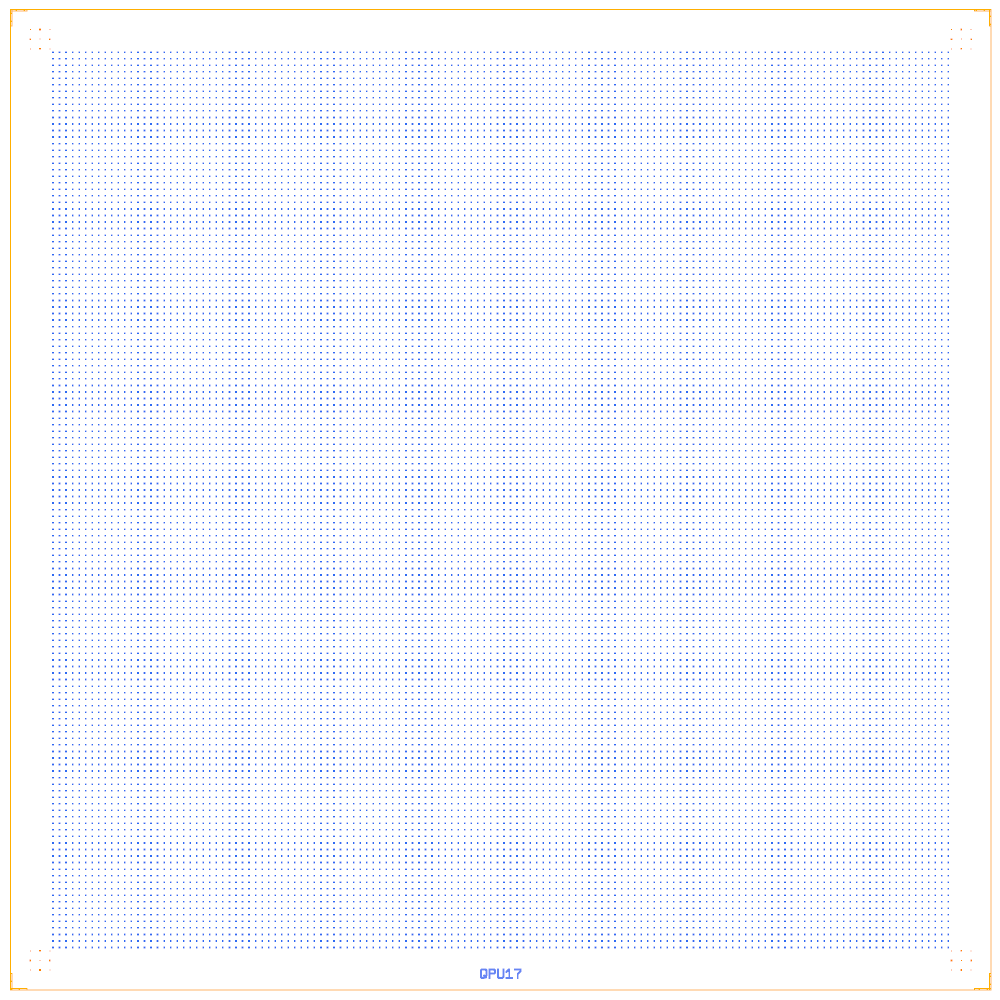

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/devicelayout/demoqpu17_s1_die.png')

In [8]:
HOLES = {"size": 10.0, "gap": 90.0, "rows": 1000,  # DeviceLayout autofill!: r = 5 µm holes on a 100 µm grid,
         "clearance": 50.0 - get_pdk().keepout.route_margin,   # a 50 µm halo round all geometry (3/0 adds 10 µm),
         "edge": 600.0}                            # none within 600 µm of the chip edge
d = Designer("demoqpu17", box=(0, 0, W, H), chip={"name_chip": "QPU17", "cheese": HOLES}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "demoqpu17_s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the PDK pad rule

The generator puts a `BondPad` (300 × 300 µm, 100 µm gap, 300 µm taper) on each used port, its port 900 µm in from
the edge, so that its etch would end 200 µm from the die edge, as in DeviceLayout. In the Quantcore PDK the outer edge
of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did: `edge="auto"`
slides each pad perpendicular to its nearest edge until it is there. Its position along the edge is kept, so every
line still leaves its pad on the pad's axis and only its first straight gets longer. The table measures it on the
built layout (its first rows; the line above it counts all 42).

`add` places plan instances (qubits with their junctions, bond pads with the pad rule) in one batch; the segments below
use it for every stage. (`S17.build` would add the whole plan in one call, without the pad rule.)

Counter({'BondPad': 42, 'AirbridgeConnection': 37, 'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4})
42 of 42 pads have their etch 100.0 µm from the die edge


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| L1 | `BondPad` | n | 100.0 | ✓ |
| L2 | `BondPad` | n | 100.0 | ✓ |
| L3 | `BondPad` | n | 100.0 | ✓ |
| L4 | `BondPad` | n | 100.0 | ✓ |
| L5 | `BondPad` | n | 100.0 | ✓ |
| L7 | `BondPad` | n | 100.0 | ✓ |
| … | | | | |

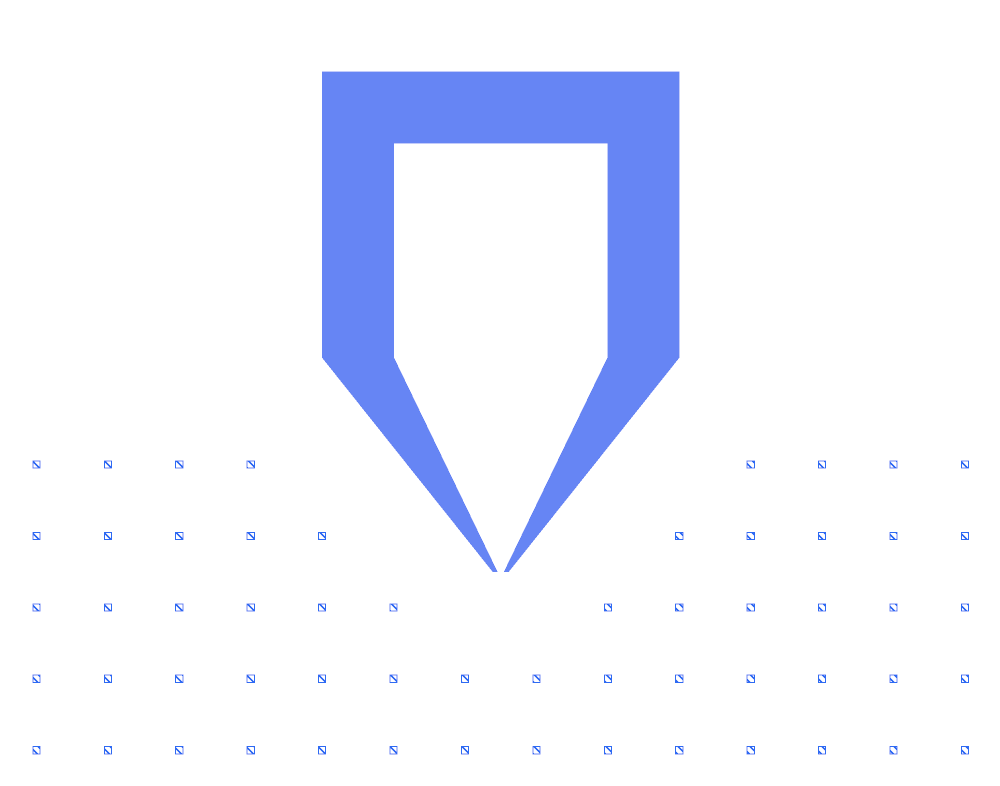

**On the chip so far:** 42 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 42 component(s) `L1`, `L2`, `L3`, `L4`, `L5`, `L7`, `L8`, `L9` … (+34).

WindowsPath('examples/designs/devicelayout/demoqpu17_s2_pads.png')

In [9]:
INST = PLAN["instances"]


def add(names):
    """Add plan instances in one batch: qubits with their junctions, bond pads with the PDK pad rule."""
    with d.batch():
        for n in names:
            s = INST[n]
            params, jj = JJ.get(n, ({}, None))
            d.add(n, s["cell"], at=tuple(s["at"]), rot=s["rot"], **({"junction": jj} if jj else {}),
                  **({"edge": "auto"} if s["cell"] == "BondPad" else {}), **s["params"], **params)


add([n for n, s in INST.items() if s["cell"] == "BondPad"])
rebuild(d)
print(Counter(s["cell"] for s in INST.values()))
rows = pads_md(d).splitlines()
print(sum("✓" in r for r in rows[2:]), "of", len(rows) - 2, "pads have their etch", get_pdk().frame.pad_edge,
      "µm from the die edge")
display(Markdown("\n".join(rows[:8] + ["| … | | | | |"])))
px, py = port_xy(d, "L5.a")                       # Q33's Z pad (port 5, top edge)
layout_step(d, OUT / "demoqpu17_s2_pads.png", box=(px - 700, H - 1100, px + 700, H), size=(1000, 786), width=400)

## Design 3 · Readout: the tees, the input capacitors and the four feedlines

The readout line needs no qubit, so it comes first:
- **`metal:CapNInterdigitalTee`:** the capacitive tee where a Purcell filter taps its feedline (8 fingers; κ_filter ≈
  30 MHz). `prime_start` / `prime_end` are the feedline ports, `second_end` the filter's.
- **`FingerCapacitorSquare`** (KQC): each feedline's series input capacitor (6 fingers), 700 µm from its input pad, for
  DeviceLayout's `ExampleSeriesClawCapacitor`.

**Lines from the plan** (`add_lines(kinds)`): `S17.routes_of(line)` turns a planned line into qcc routes, one per
section between its airbridges, the bridges being `AirbridgeConnection` instances (`AB_<line>_<k>`) placed over the
line below. The plan has already found every crossing and decided which line passes over (couplers < resonators <
feedlines < Z < XY), and each line's airbridges come with it. So the segments can draw the kinds in a designer's
order (here the feedlines first, the lower-ranked resonators and couplers later): a bridge that carries a feedline
over a lower-ranked line is placed now, at the crossing the plan computed, and that line is drawn under it in a later
segment. `add_lines` is the v1 notebook's own helper, unchanged.

**The feedlines** (`add_lines({"feed"})`): input pad → series capacitor → each tee in order → output pad
(10/6 µm). They need the pads (Design 2), the input capacitors and the tees (this cell): `placed_for` checks it from
the plan (`S17.needs`) before drawing. Feedline 1 dips into the channel between Q32's Z line and Q22's XY line to reach Q33's tee (`stubs`,
Plan 2).

T_Q33: ['prime_end', 'prime_start', 'second_end'] | CIN_1: ['a', 'b']


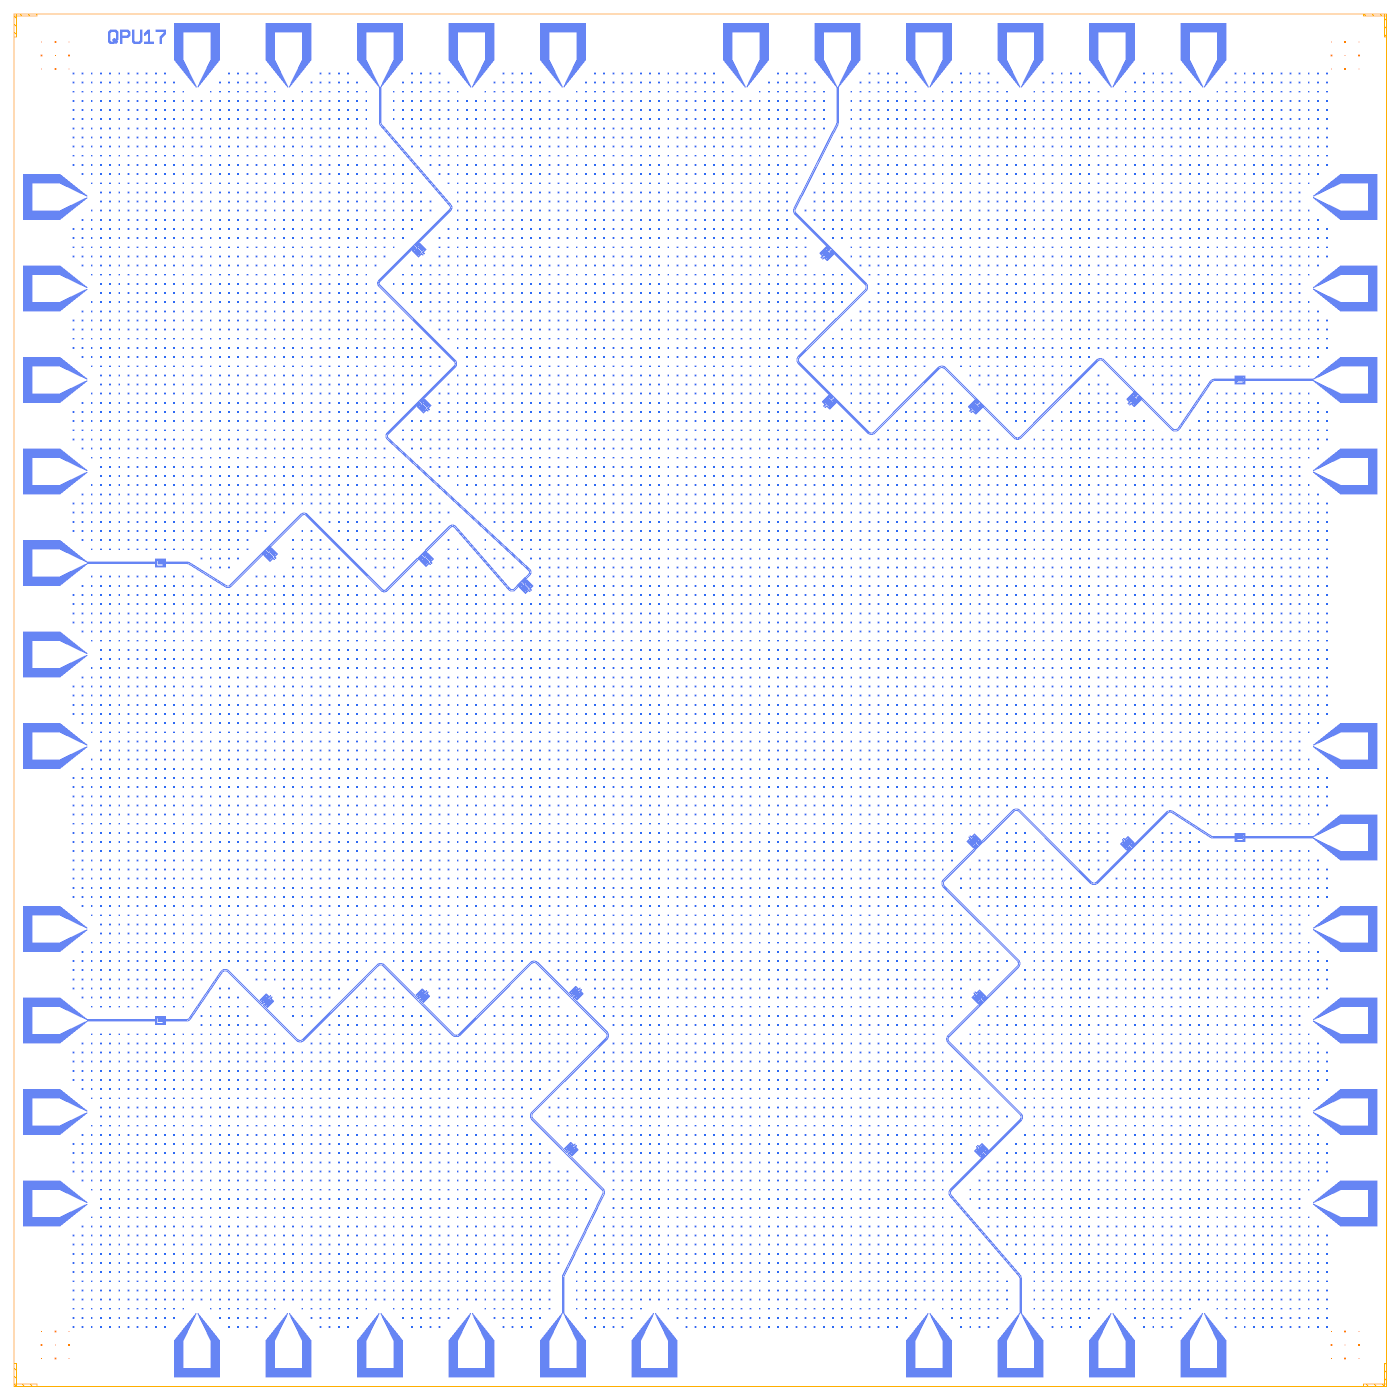

**On the chip so far:** 42 pads · 0 qubits · 21 other components · 25 routes · 0 declared couplings. **This step added** 21 component(s) `T_Q12`, `T_Q13`, `T_Q22`, `T_Q23`, `T_Q24`, `T_Q25`, `T_Q31`, `T_Q32` … (+13) and 25 route(s) `FL1_in`, `FL1_0`, `FL1_1`, `FL1_2`, `FL1_3`, `FL1_4`, `FL1_5`, `FL2_in` … (+17).

WindowsPath('examples/designs/devicelayout/demoqpu17_s3_readout_line.png')

In [10]:
def add_lines(kinds):
    """Add the planned lines of these kinds: the airbridges they pass over others on, then one route per section."""
    with d.batch():
        for line in PLAN["lines"]:
            if line.kind not in kinds:
                continue
            for k in range(len(line.bridges)):
                name = f"AB_{line.name}_{k}"
                s = INST[name]
                d.add(name, s["cell"], at=tuple(s["at"]), rot=s["rot"], **s["params"])
            for r in S17.routes_of(line):
                d.route(r["name"], r["start"], r["end"], type="cpw", nodes=[tuple(n) for n in r["nodes"]],
                        a=line.a, b=line.b, r=line.r)


def placed_for(kinds):
    """Stop if a planned line of these kinds starts or ends on an instance that is not placed yet (``S17.needs``: the
    plan's own port references), so a reordered notebook fails here, with the names, and not in the router."""
    missing = S17.needs(PLAN, kinds) - set(d.data["instances"])
    assert not missing, f"the {sorted(kinds)} lines need {sorted(missing)} placed first"


add([n for n, s in INST.items() if s["cell"] in ("metal:CapNInterdigitalTee", "FingerCapacitorSquare")])
placed_for({"feed"})
add_lines({"feed"})
print("T_Q33:", sorted(d["T_Q33"].ports), "| CIN_1:", sorted(d["CIN_1"].ports))
layout_step(d, OUT / "demoqpu17_s3_readout_line.png", size=(1400, 1400), width=560)

## Design 4 · Qubit placement: 17 StarQubits

- **`metal:StarQubit`** (Quantum Metal's star transmon, standing in for DeviceLayout's wedge star): a star-shaped
  island in a 150 µm pocket with five pads — four couplers (`pin_cpl1` … `pin_cpl4`: E, N, W, S) and a readout pad
  (`pin_rdout`) on the qubit's readout diagonal, all pins 1.25 × the radius (187.5 µm) from the centre. The SQUID sits
  in the 90° gap between the E and N couplers (`squid_a` / `squid_b` are its attachment points; the cell draws it). The
  `rotation_*` options turn each qubit's readout pad and SQUID into the quadrant of its feedline. A narrower readout gap
  on the data qubits (8 µm vs 15 µm) stands in for their larger readout coupler.

Each gets its trilayer SQUID from the plan's sizing (Plan 3, `JJ`). The second picture zooms on the centre: Q33's
closed plaquette.

Q33 ports: ['pin_cpl1', 'pin_cpl2', 'pin_cpl3', 'pin_cpl4', 'pin_rdout', 'squid_a', 'squid_b']


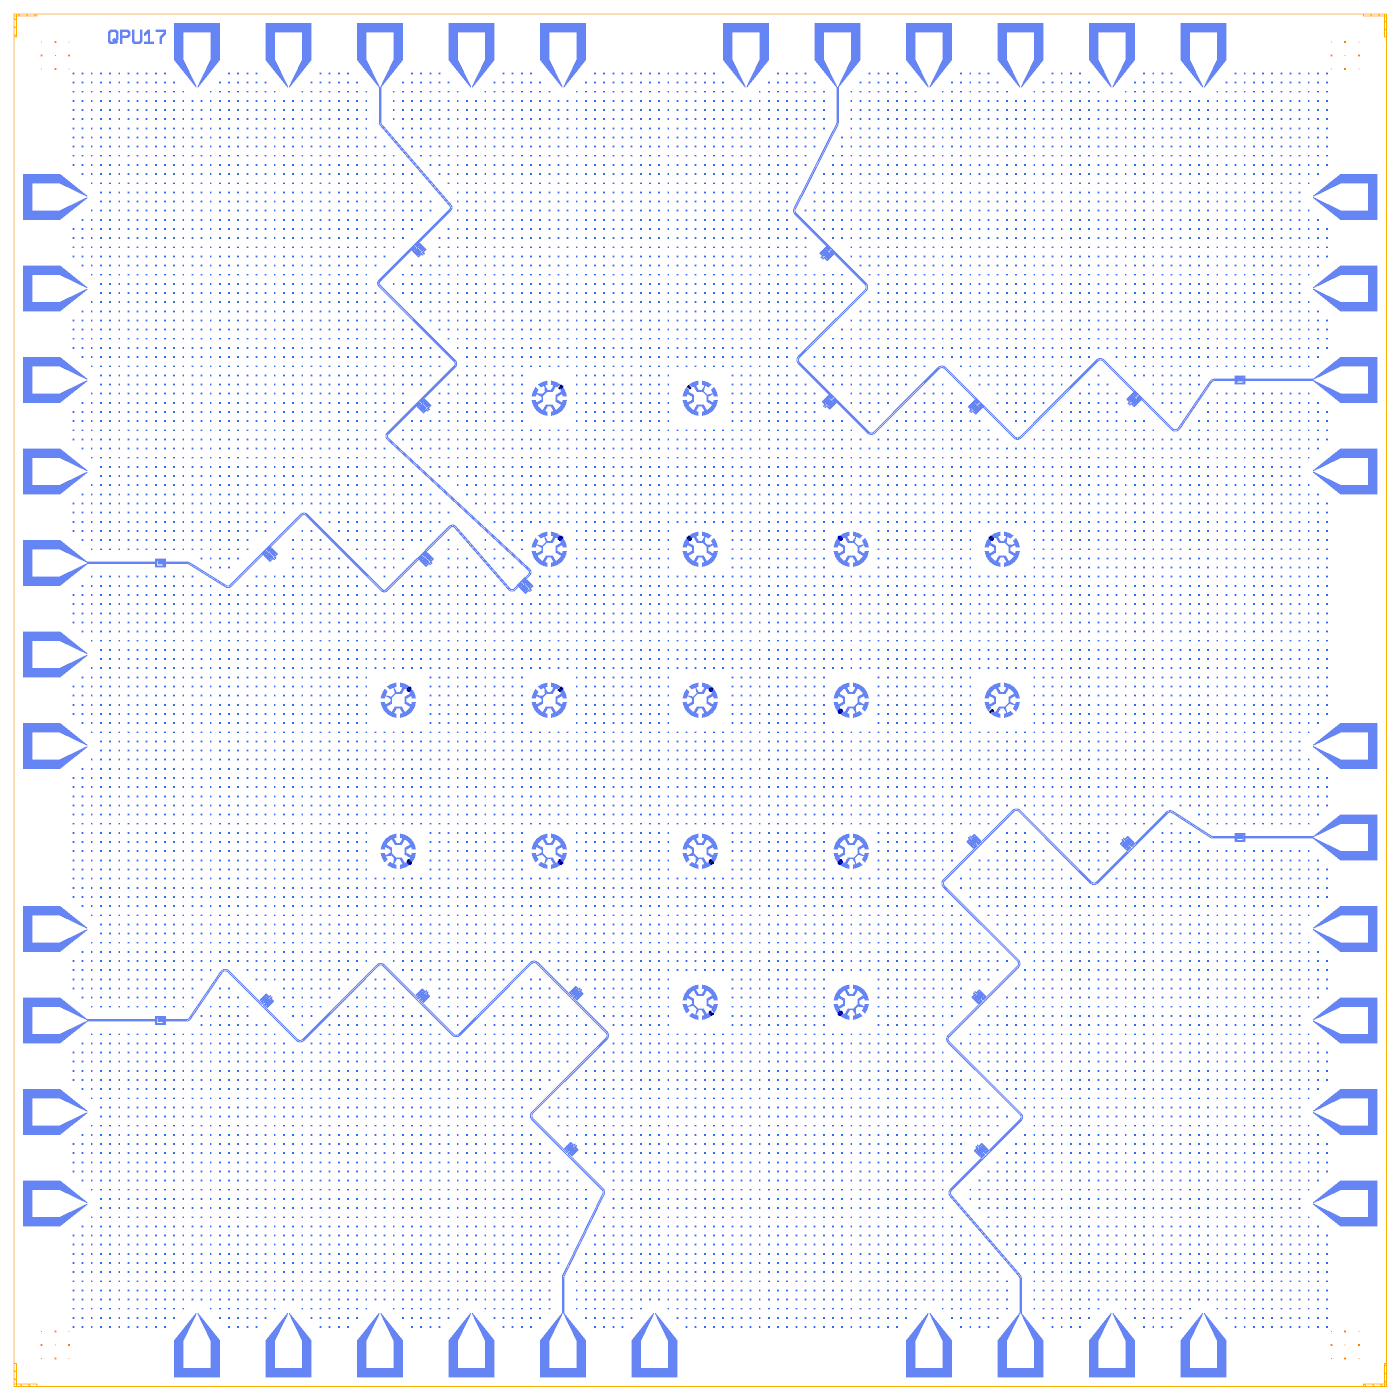

**On the chip so far:** 42 pads · 17 qubits · 21 other components · 25 routes · 0 declared couplings. **This step added** 17 component(s) `Q12`, `Q13`, `Q22`, `Q23`, `Q24`, `Q25`, `Q31`, `Q32` … (+9).

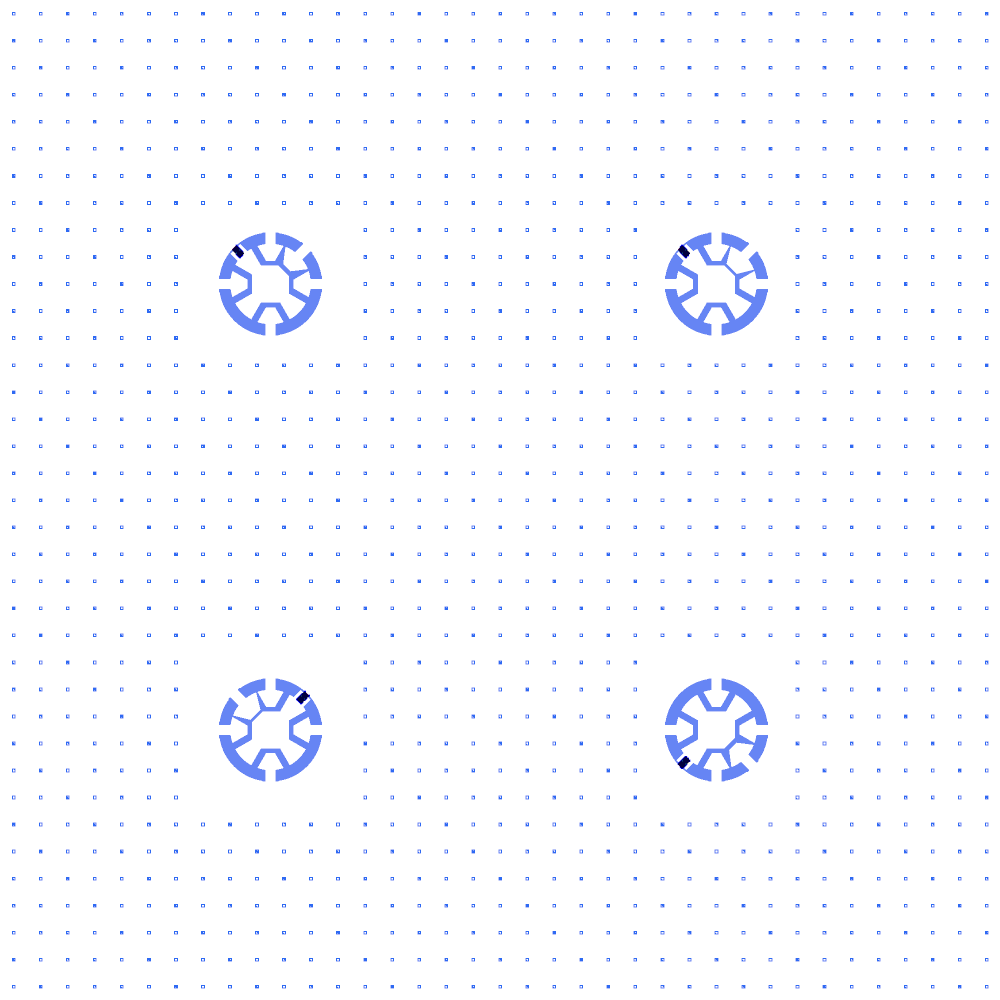

WindowsPath('examples/designs/devicelayout/demoqpu17_step_parts.png')

In [11]:
add([n for n, s in INST.items() if s["cell"] == "metal:StarQubit"])
print("Q33 ports:", sorted(d["Q33"].ports))
layout_step(d, OUT / "demoqpu17_s4_qubits.png", size=(1400, 1400), width=560)
snap(d, OUT / "demoqpu17_step_parts.png", box=(7500 - 1000, 7500 - 1000, 7500 + 2700, 7500 + 2700),
     size=(1000, 1000), width=420)

## Design 5 · Readout: the readout and Purcell λ/4s

**The readout modules** (`add_lines({"resonator"})`): the readout λ/4 hairpin from the readout pad,
shorted at its end, and the Purcell λ/4 hairpin from the tee's coupled port, shorted; the tap between them is a
declared capacitance (`d.couple`, 1.2 fF, not drawn). Each readout starts on its qubit's readout pad, each filter on
its tee's coupled port, so both need the qubits and the tees (`placed_for`). Q33's closed-plaquette module keeps both hairpins inside the plaquette, its tee in the west channel
and its filter lead bridged over a coupler (Plan 2). The second picture is the v1's view of the whole chip with its
modules.

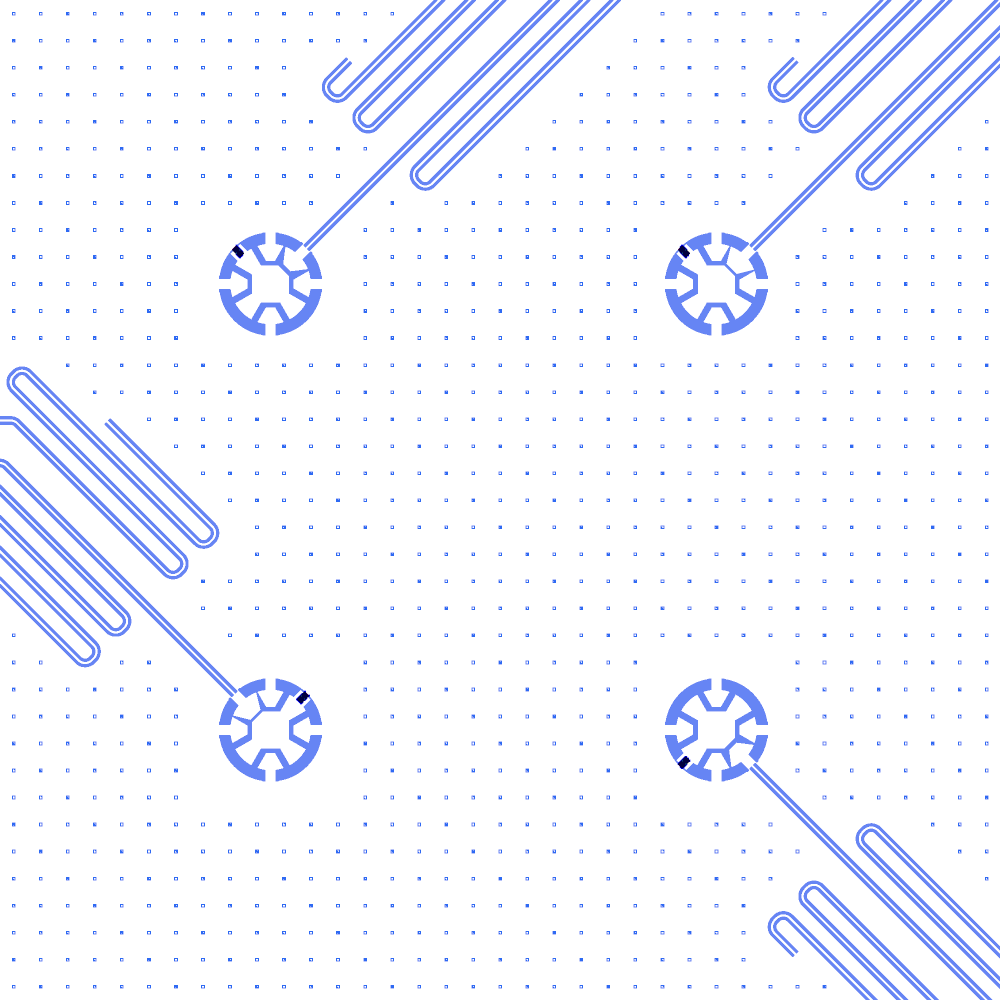

**On the chip so far:** 42 pads · 17 qubits · 22 other components · 60 routes · 17 declared couplings. **This step added** 1 component(s) `AB_PF_Q33_0` and 35 route(s) `RO_Q12`, `PF_Q12`, `RO_Q13`, `PF_Q13`, `RO_Q22`, `PF_Q22`, `RO_Q23`, `PF_Q23` … (+27).

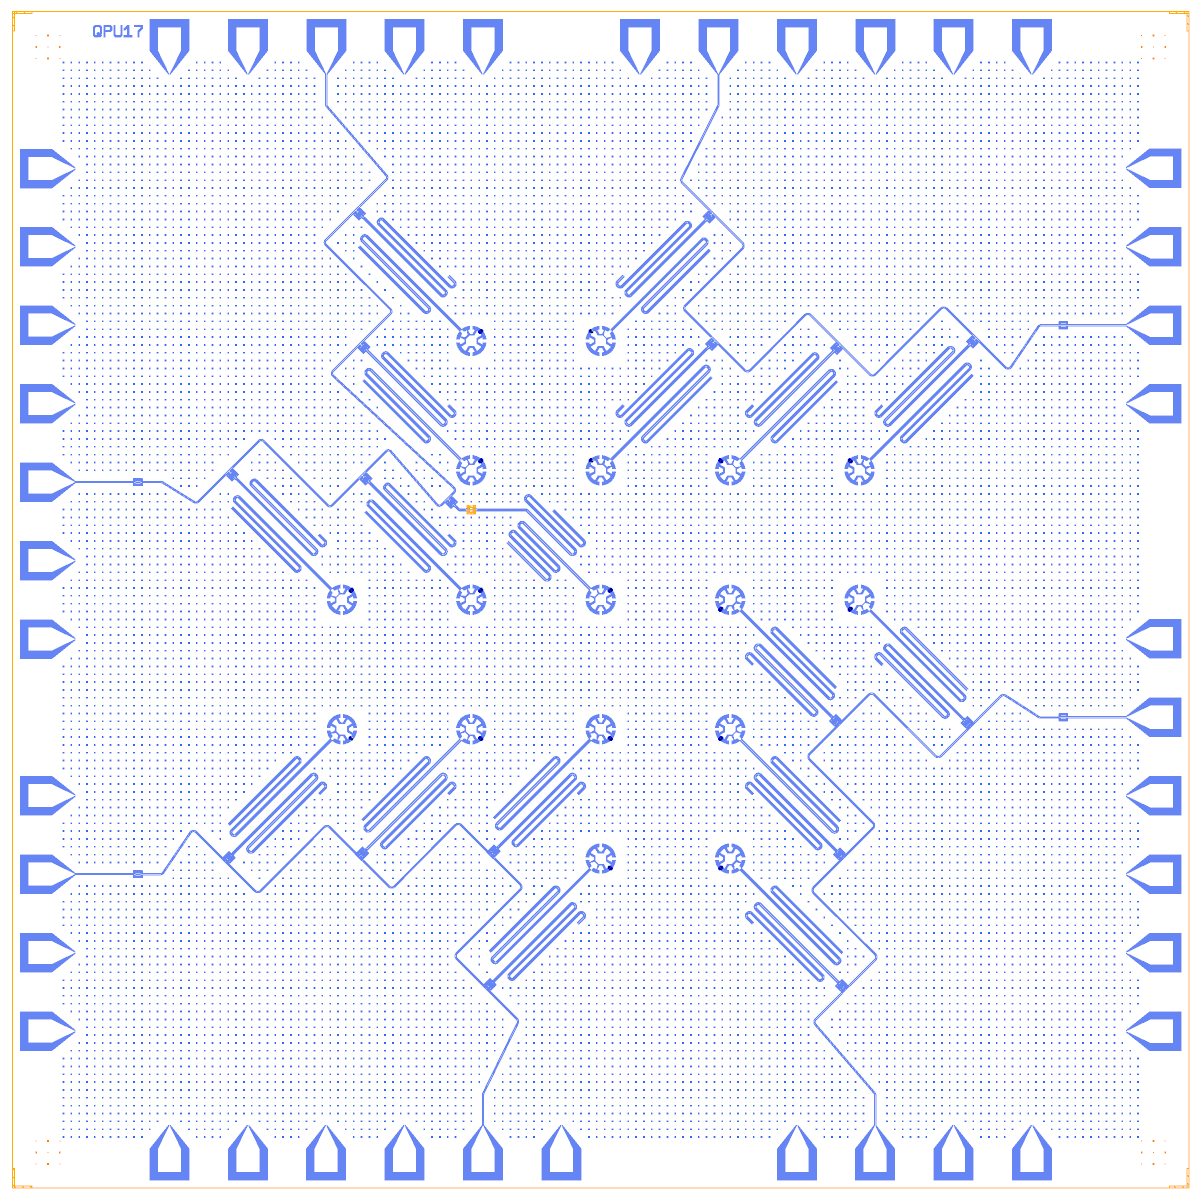

WindowsPath('examples/designs/devicelayout/demoqpu17_step_modules.png')

In [12]:
placed_for({"resonator"})
add_lines({"resonator"})
with d.batch():
    for name, a, b, c, note in PLAN["couplings"]:  # the readout–Purcell taps: declared, not drawn
        d.couple(name, a, b, C_fF=c, note=note)
layout_step(d, OUT / "demoqpu17_s5_readouts.png", box=(7500 - 1000, 7500 - 1000, 7500 + 2700, 7500 + 2700),
            size=(1000, 1000), width=420)
snap(d, OUT / "demoqpu17_step_modules.png", size=(1200, 1200), width=480)

## Design 6 · Coupling: the 24 nearest-neighbour couplers

**The couplers** (`add_lines({"coupler"})`): straight 10/10 µm CPWs between facing coupler pads. They
have the lowest rank: other lines pass over them, never the other way round. Each joins two qubits' coupler pads
(`placed_for` checks the qubits).

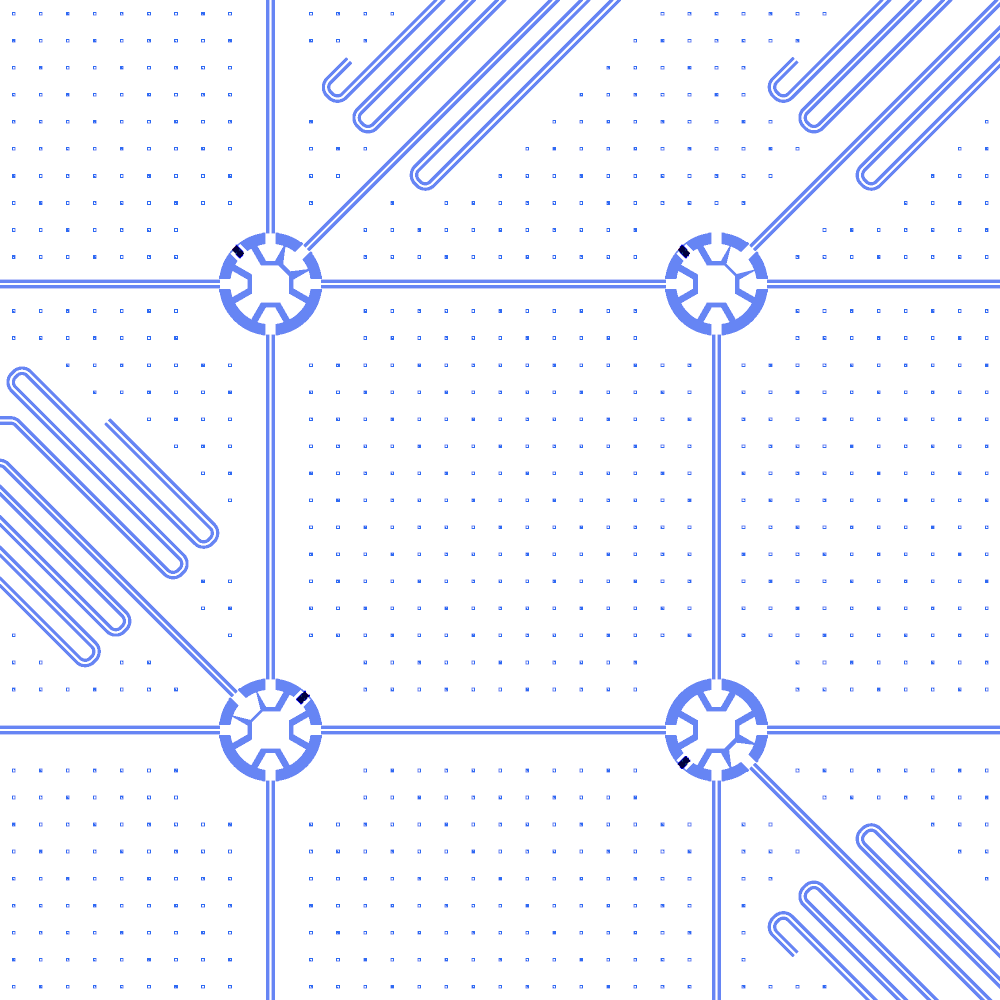

**On the chip so far:** 42 pads · 17 qubits · 22 other components · 84 routes · 17 declared couplings. **This step added** 24 route(s) `CPL_Q12_Q13`, `CPL_Q12_Q22`, `CPL_Q13_Q23`, `CPL_Q22_Q23`, `CPL_Q22_Q32`, `CPL_Q23_Q24`, `CPL_Q23_Q33`, `CPL_Q24_Q25` … (+16).

WindowsPath('examples/designs/devicelayout/demoqpu17_s6_couplers.png')

In [13]:
placed_for({"coupler"})
add_lines({"coupler"})
layout_step(d, OUT / "demoqpu17_s6_couplers.png", box=(7500 - 1000, 7500 - 1000, 7500 + 2700, 7500 + 2700),
            size=(1000, 1000), width=420)

## Design 7 · Routing: the Z and XY lines

**The Z, then XY lines** (`add_lines({"z", "xy"})`): pad → a strip beside the module → the SQUID (Z,
shorted beside it, after passing over the qubit's own N coupler) or the drive end (XY, open, between the readout pad
and a coupler). They start on their pads and end free beside their qubit, so they need only the pads; their airbridges
over the feedlines, couplers and modules come with them. Q33's XY line comes in from the left under row 3 and its Z line from the top through the plaquette
Q12–Q23 (`vias`, Plan 2). After this segment every planned instance and route is on the chip (the line below checks
it).

117 instances, 154 routes, 37 airbridges; not placed: none


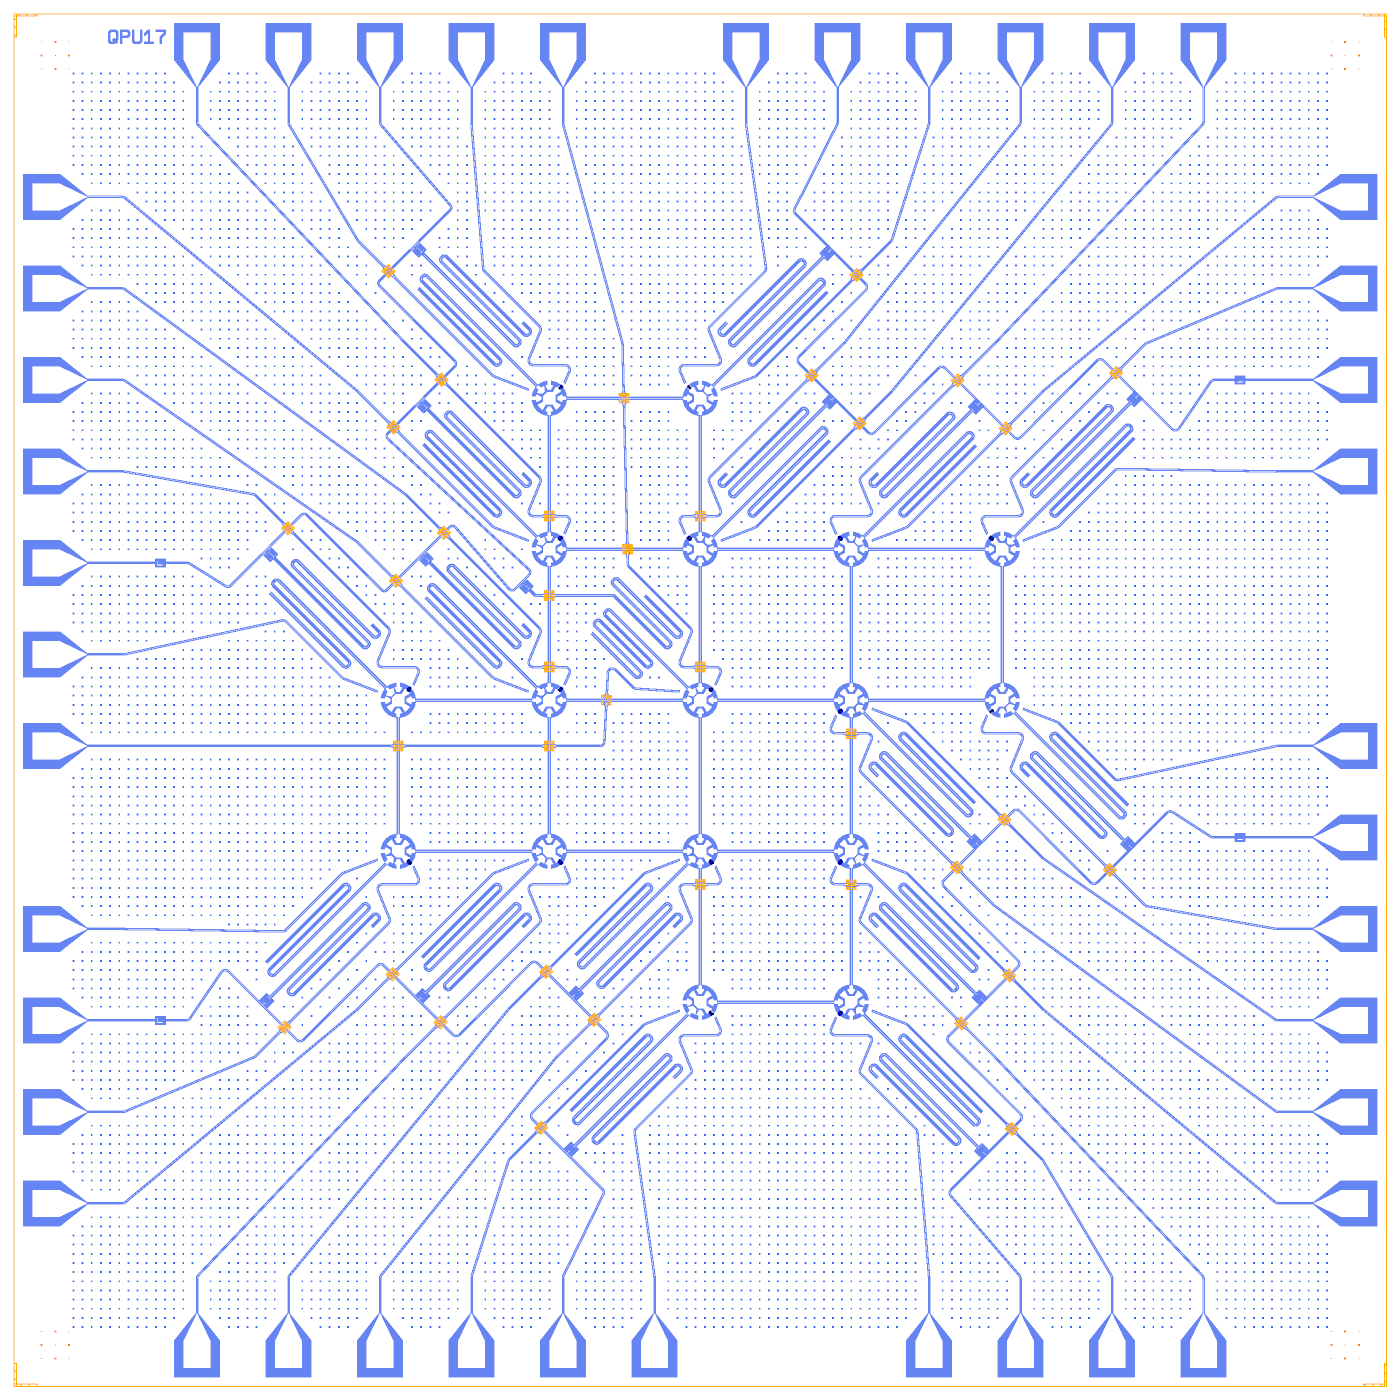

**On the chip so far:** 42 pads · 17 qubits · 58 other components · 154 routes · 17 declared couplings. **This step added** 36 component(s) `AB_XY_Q12_0`, `AB_XY_Q13_0`, `AB_Z_Q22_0`, `AB_Z_Q22_1`, `AB_XY_Q22_0`, `AB_Z_Q23_0`, `AB_Z_Q23_1`, `AB_XY_Q23_0` … (+28) and 70 route(s) `Z_Q12`, `XY_Q12`, `XY_Q12_1`, `Z_Q13`, `XY_Q13`, `XY_Q13_1`, `Z_Q22`, `Z_Q22_1` … (+62).

WindowsPath('examples/designs/devicelayout/demoqpu17_s7_control.png')

In [14]:
placed_for({"z", "xy"})
add_lines({"z", "xy"})
missing = set(INST) - set(d.data["instances"])
print(len(d.data["instances"]), "instances,", len(d.data["routes"]), "routes,", len(PLAN["bridges"]), "airbridges;",
      "not placed:", missing or "none")
layout_step(d, OUT / "demoqpu17_s7_control.png", size=(1400, 1400), width=560)

## Design 8 · The whole chip: targets, sim groups, centring, save

- **Targets** (`d.targets`): the plan's f_q per qubit and `params.jl`'s readout f_r. The LOM tables show them in
  brackets, and the DRC's `pdk_fq` reads the f_q targets.
- **Sim groups** for the FEM jobs (Simulate 1–4): `Q23_Q33` is a Q3D C-matrix of the auxiliary qubit Q23, the data qubit
  Q33 and their 1.3 mm coupler; `Q12_readout` an eigenmode / EPR job of Q12 with its readout hairpin, tee and Purcell
  filter; `Q33_readout` the same for Q33's closed-plaquette module, whose filter lead is bridged over a coupler. It keeps
  that airbridge (`settings={"airbridges": True}`): without it the filter lead would be open at the crossing.
- **Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of
  everything placed (components and routes) and shifts the design so its centre is the die centre (pads keep their
  100 µm: they slide back to the edge); it moves nothing when the content is within 50 µm of the centre. The lattice is
  centred on Q33 and the pads sit on all four edges, so no shift is expected.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the previous
run's): the segments changed how the chip is built, not the chip, so it should say *same design*. The file keeps the
previous key order (the feedlines, readouts and couplers were added in another order here), so `git diff` stays
empty. (`chain(q)` lists a module's routes and airbridges in the order they were added; one `add_lines` call adds
each kind in the plan's order, so the `Q33_readout` selection is the v1's list.)

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/devicelayout/demoqpu17.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer demoqpu17: 117 instances, 154 routes, live=False> → examples\designs\devicelayout\demoqpu17.json
Q33's routes (µm): {'RO_Q33': 4440.6, 'PF_Q33': 134.1, 'PF_Q33_1': 4081.2, 'CPL_Q23_Q33': 1275.0, 'CPL_Q32_Q33': 1275.0, 'CPL_Q33_Q34': 1275.0, 'CPL_Q33_Q43': 1275.0, 'Z_Q33': 3403.1, 'Z_Q33_1': 1483.6, 'Z_Q33_2': 1635.2, 'Z_Q33_3': 329.2, 'XY_Q33': 3316.6, 'XY_Q33_1': 1483.2, 'XY_Q33_2': 914.7, 'XY_Q33_3': 1106.5}


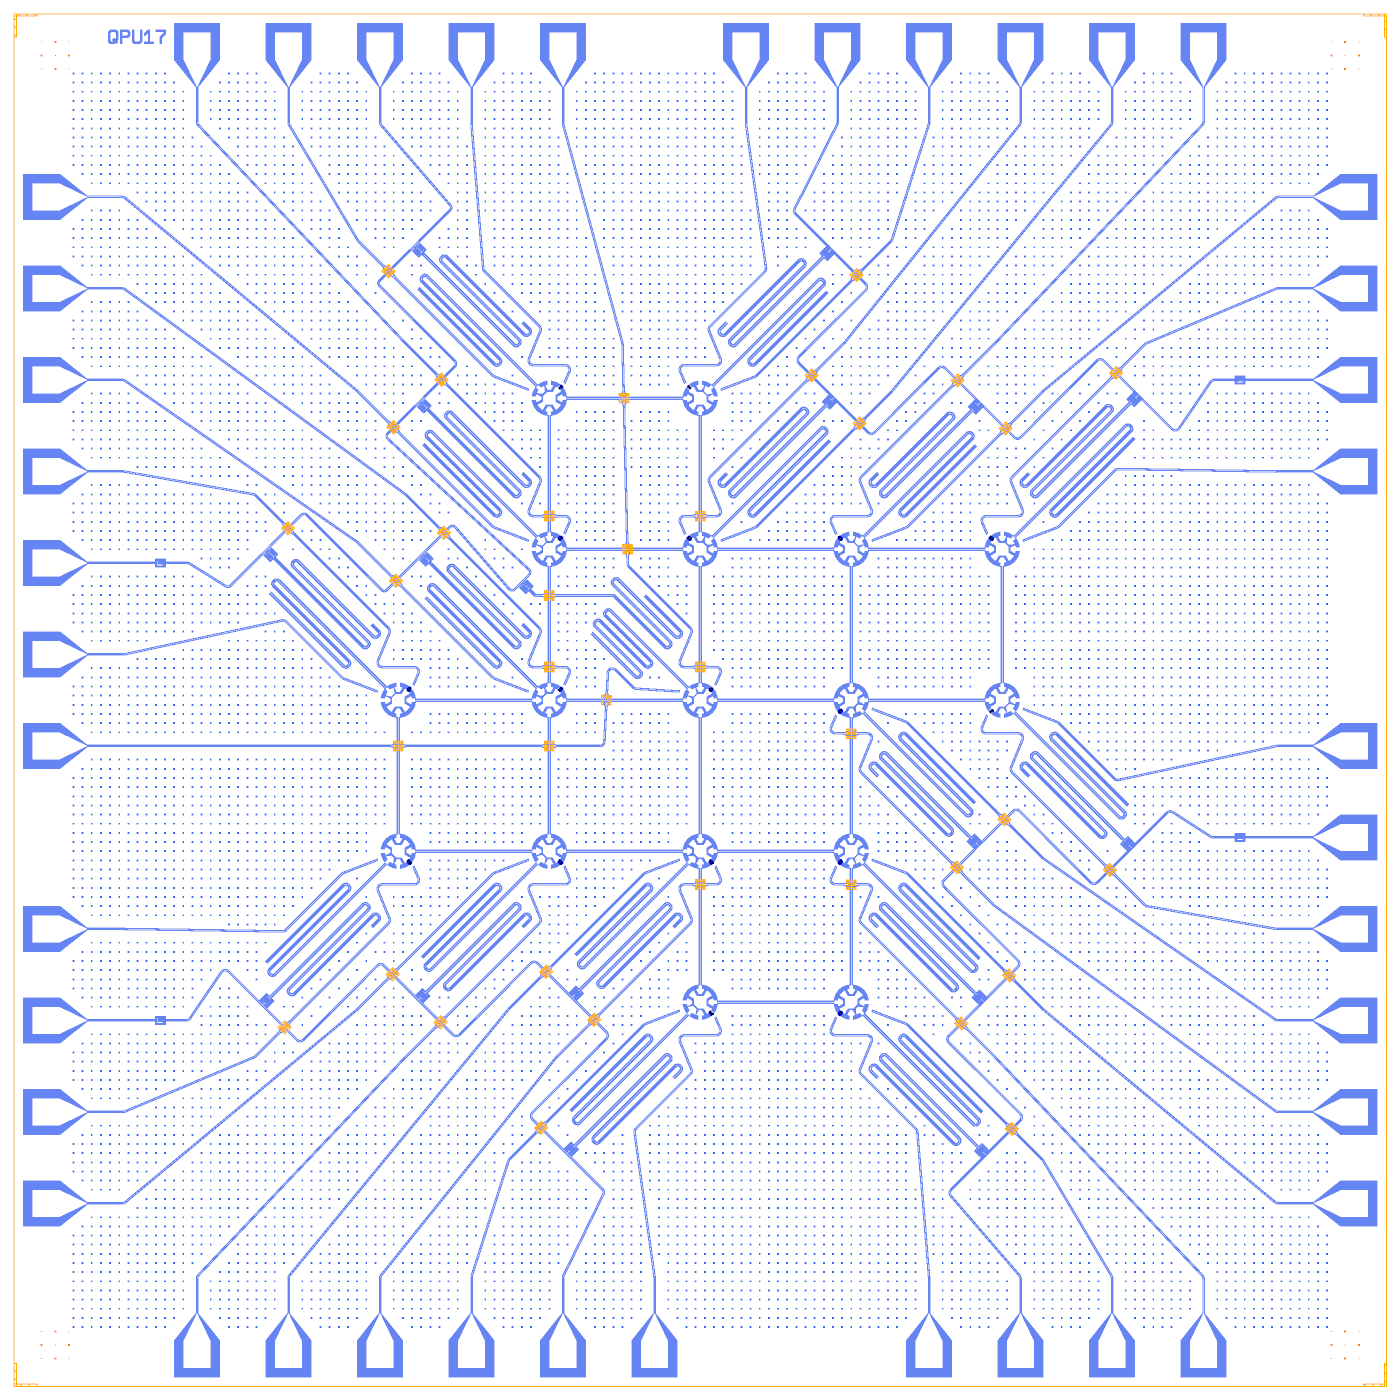

**On the chip so far:** 42 pads · 17 qubits · 58 other components · 154 routes · 17 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/devicelayout/demoqpu17_step_routes.png')

In [15]:
def chain(q):
    """A qubit's readout chain: the qubit, its readout and Purcell routes and the airbridges on them."""
    return [q, *[r for r in d.data["routes"] if r.startswith((f"RO_{q}", f"PF_{q}"))],
            *[i for i in d.data["instances"] if i.startswith((f"AB_RO_{q}", f"AB_PF_{q}"))]]


with d.batch():
    d.targets(**{q: {"f_q_GHz": F_Q[q]} for q in LABELS.values()},
              **{f"RO_{q}": {"f_GHz": F_RO[q]} for q in LABELS.values()})
    d.sim_group("Q23_Q33", ["Q23", "Q33", "CPL_Q23_Q33"], margin_um=150, analyses=["q3d_cmatrix"])
    d.sim_group("Q12_readout", ["Q12", "RO_Q12", "T_Q12", "PF_Q12"], margin_um=150, analyses=["eigenmode_epr"])
    d.sim_group("Q33_readout", chain("Q33") + ["T_Q33"], margin_um=150, analyses=["eigenmode_epr"],
                settings={"airbridges": True})
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "demoqpu17.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("Q33's routes (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items() if "Q33" in k})
layout_step(d, OUT / "demoqpu17_step_routes.png", size=(1400, 1400), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, routes that loop over
themselves or run over a component, overlaps, the chip box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings (the first twelve are listed).


Expected (from the v1 run): **no errors**; 54 `dangling_port` warnings: 34 are the qubits' `squid_a` / `squid_b` (the junction
attachment points: the cell draws the SQUID itself, nothing is routed there) and 20 are the coupler pads of edge qubits
with no neighbour on that side (DeviceLayout grounds them; here they are left free). **12 PDK design warnings**, all
`pdk_rn`: the nine data SQUIDs (66.2–75.0 kΩ) and the auxiliaries Q12, Q23, Q25 (51.1–53.6 kΩ). No `pdk_fq` (the plan
is inside 4–8 GHz), no `pad_edge` (the 42 pads sit at 100 µm), no overlaps, no route looping over itself or over a
component. `pdk_report` gives the original's cheese rule, a content centre at (+0, +0) and "Quantcore Squid × 17".

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist: the 17-qubit node structure

`d.lom()` turns the layout into a lumped circuit:
- each `StarQubit` → a grounded island with its SQUID, plus a node per pad;
- each coupler → a wire joining two coupler pads into one node (C_g – node – C_g between the two islands);
- each readout and each filter → a λ/4 `TLres`: the readout's open end on the readout-pad node, the filter's on its
  tee's coupled node; the tee's IDC joins that node to the feedline node; `K_<q>` is the readout–filter tap;
- each feedline → one node carrying its tees, with a 50 Ω port behind its series input capacitor and one at its output
  pad;
- the XY and Z lines → stubs on their pads (no drive or flux control: `StarQubit` has no drive or flux port). Lines
  with airbridges are joined through the bridges.

The table gives each qubit's role, its neighbours, its two λ/4 lines (estimated frequency and open-end node) and its
feedline node. The four feedline nodes should carry 5, 4, 4 and 4 tees.

In [ ]:
lb = d.lom()
m = lb.model
print(netlist_md(lb).splitlines()[0])
print(Counter(b.type for b in m.branches.values()))


def tl(name):
    return next((b for n, b in m.branches.items() if b.type == "TLres" and n.startswith(name)), None)


rows = ["| qubit | role | coupled to | readout λ/4 (GHz) · node | Purcell λ/4 (GHz) · node | feedline node |",
        "|---|---|---|---|---|---|"]
for site, q in LABELS.items():
    nb = [b if a == q else a for _, a, b in S17.neighbours(LABELS) if q in (a, b)]
    ro, pf = tl(f"RO_{q}"), tl(f"PF_{q}")
    rows.append(f"| {q} | {'data' if q in DATA else 'aux'} | {', '.join(nb)} | {(ro.value or {}).get('f_GHz', 0):.3f} · "
                f"`{ro.nodes[0]}` | {(pf.value or {}).get('f_GHz', 0):.3f} · `{pf.nodes[0]}` | "
                f"`{lb.port_map.get(f'T_{q}.prime_start')}` |")
display(Markdown("\n".join(rows)))
print("tees per feedline node:", dict(Counter(lb.port_map.get(f"T_{q}.prime_start") for q in LABELS.values())))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation against the targets

Each qubit is simulated with its readout chain (readout λ/4, tap, Purcell λ/4, tee and the airbridges on them) and its
**whole feedline** (all its tees, the input capacitor, both 50 Ω ports), so that κ is the decay through the filter into
the line: QuCat normal modes, QuTiP dressed values, the targets in brackets. Then Q23 and Q33 with their coupler: the
two qubit modes and the static ZZ.


What the tables show (from the v1 run):
- **Frequencies.** The readouts land within 1.2 % of `params.jl` (6.766 … 7.588 GHz): the data qubits' 0.5–1.2 % low,
  the auxiliaries' 0–0.6 % high. The dressed qubits sit 2.7–4.9 % below the plan (data 4.67–4.95 GHz, auxiliaries
  5.54–5.88 GHz): the finger-grid steps of Plan 3 and the pull of the readout pad.
- **Filters.** Each Purcell filter hybridises with its readout: the two modes sit 37–52 MHz apart, and the filter-like
  mode has κ ≈ 27–38 MHz.
- **κ_r** through the filter: 4.3–6.2 MHz for the data qubits, 1.4–5.1 MHz for the auxiliaries.
- **α** −215 … −224 MHz (data) and −193 … −209 MHz (aux).
- **χ** of the readout mode −8.2 … −11.9 MHz (data) and −11.3 … −22.9 MHz (aux, closer to their readouts): large,
  because the StarQubit LOM gives all five pads the same arc, so the readout pad couples as strongly as a coupler pad
  (the FEM jobs, Simulate 2–3, calibrate it).
- **Q23 + Q33:** two qubit modes 0.86 GHz apart (no hybridisation) and a static ZZ of −20.6 MHz, far too strong: the
  LOM has no line capacitance for a pad-to-pad coupler route (an open LOM request, as in `metal/m53_wallraff_17q`;
  the `Q23_Q33` C-matrix job measures it).

In [ ]:
def feed(ln):
    """A feedline: its pads, input capacitor, sections and tees."""
    spec = FEEDLINES[ln]
    return [spec["pad_in"], spec["pad_out"], f"CIN_{ln}", *[r for r in d.data["routes"] if r.startswith(f"FL{ln}_")],
            *[f"T_{q}" for q in spec["qubits"]]]


GROUPS = {q: chain(q) + feed(ln) for ln, spec in FEEDLINES.items() for q in spec["qubits"]}
res = simulate_groups(d, GROUPS, max_modes=3)
display(Markdown(groups_md(res, d.data["targets"])))
pair = simulate_groups(d, {"Q23+Q33": ["Q23", "Q33", "CPL_Q23_Q33"]}, max_modes=2)
display(Markdown(modes_md(pair["Q23+Q33"]) + "\n\n" + zz_md(pair)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares the
readout and filter modes; filled markers are the QuTiP dressed values; red bars the plan's targets), (b) the dispersive
shift |χ| of each readout and filter mode. From the v1 run the readouts sit within 1.2 % of `params.jl` and each filter
37–52 MHz from its readout, while the qubits fall 2.7–4.9 % below the plan (the finger grid, Plan 3).

In [ ]:
plot_lom({**res, **pair}, OUT / "demoqpu17_lom.png", targets=d.data["targets"], title="demoqpu17: LOM per qubit group")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property, re-run the LOM and compare. Q13 is a data qubit with the narrow 8 µm readout gap: widen it
to 15 µm (the auxiliary value). The readout pad's coupling to the island drops, so |χ| and the qubit's pull on its
readout drop. The pins do not move (they sit at 1.25 × the pocket radius), so every route stays where it is; the DRC
line checks it.


Result (from the v1 run): |χ| of the readout mode drops from 8.74 to 4.14 MHz; f_q rises by 78 MHz (4.671 → 4.749 GHz) and α
goes from −223 to −233 MHz; the readout moves up by 61 MHz (7.228 → 7.288 GHz), past its filter (now 7.257 GHz), so the
two hybridised modes mix more: the readout's κ rises from 4.3 to 13.3 MHz and the filter's falls from 34.6 to 25.6 MHz.
The DRC stays clean (the same 54 warnings and 12 PDK design warnings).

In [ ]:
d2 = design_copy(DESIGN)
d2["Q13"].set(gap_readout=15)
after = simulate_groups(d2, {"Q13": GROUPS["Q13"]}, max_modes=3)
display(Markdown(params_delta_md({"Q13": res["Q13"]}, after)))
print("DRC after the change:", drc_md(d2.drc()).splitlines()[0])

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/devicelayout/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group out
of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for: a note then flags each
crossing bridge, whose line is open at the crossing in the FEM model. `Q33_readout` keeps them
(`settings={"airbridges": True}`; `build_simulation(..., airbridges=True)` and the CLI's `--airbridges` do the same):
the loop below the table shows both.

Three jobs:
- **`Q23_Q33`** (Q3D C-matrix): Q23, Q33 and their coupler. It gives C_Σ, the pad capacitances and g;
- **`Q12_readout`** (eigenmode / EPR): Q12 with its readout hairpin, tee and Purcell hairpin: f_r, κ and χ by EPR;
- **`Q33_readout`** (eigenmode / EPR): Q33's closed-plaquette module with its bridged filter lead.


What the export reports (from the v1 run):
- `Q23_Q33`: 13 ports: the two junctions, the coupler's two ends at the qubit pins (`waveguide`) and nine lines the box
  cuts (`edge`); the C-matrix nets are `Q23.island`, `Q33.island` and three line sections inside the box (`XY_Q23_1`,
  `XY_Q33_3`, `Z_Q33_2`).
- `Q12_readout`: Q12's junction port and nine lines the box cuts, each ended in 50 Ω (`edge_lumped`). The box edge
  crosses seven of them at 45° (`FL1_3`, `FL1_4` twice, `FL1_5`, `XY_Q12_1`, `Z_Q22`, `Z_Q22_1`). Their ports sit on
  the line's own axis, with the cut square to the line; the builder's note lists them with their angles.
- `Q33_readout`: Q33's junction port (L 10.52 nH, C 9.6 fF: the design's junction value, the one the LOM uses) and ten
  lines; four of them cross at an angle (`FL1_2`, `FL1_3` and `Z_Q32_1` at about 45°, `XY_Q32_1` at 21°) and get the
  same ports.
- Every port has a polygon, so AEDT terminates every line (until 2026-11-18 the angled ones were cut along the box
  normal and had none). The eigenmode jobs are exported here, not solved. Airbridges: `airbridges=False` drops the three bridge shapes in the `Q33_readout` box, `True` (the
  group's setting) keeps them; the other notes are the same.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/devicelayout/fem/: solved results are kept here
from quantcore_circuits.sim_tools import build_simulation

jobs = export_sims(DESIGN, ["Q23_Q33"])
jobs_eig = export_sims(DESIGN, ["Q12_readout", "Q33_readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
for keep_ab in (False, True):                    # the group keeps its airbridges; without them the bridged lead is open
    s = build_simulation(DESIGN, "Q33_readout", "eigenmode_epr", airbridges=keep_ab)
    print(f"airbridges={keep_ab}: geometry {s.geometry} | notes {s.notes}")

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of `Q23_Q33`: Q23's and Q33's islands against ground, each other and the line sections inside the box
(C_Σ, the pad capacitances and g); the coupler enters through waveguide ports at the qubit pins. It measures the
coupling the LOM overestimates (LOM 1: the pad-to-pad coupler has no line capacitance). Each net is named after its
LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else
loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q12_readout` and `Q33_readout` boxes in HFSS eigenmode (`Q33_readout` with its airbridges, the group's
`settings`): the SQUID is a lumped L_J ‖ C_J sheet, the readout hairpin, the tee and the Purcell filter are inside, and
the lines the box cuts end in 50 Ω (those that leave it at an angle on their own axis, fixed 2026-11-18), so each
mode's Q gives κ through the filter. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns
the junction's energy participation into the dressed f_q, α and the readout's χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box: here `Q12_readout`, the feedline's S21 through Q12's tee,
with the readout's notch behind its Purcell filter. The library cannot hand the solved eigenmode **mesh** itself to a
driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and
box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's `RO_Q12`
f_r before the eigenmode is solved) and a fast sweep around it, which holds the filter mode too (37–52 MHz away in the
v1 LOM run).

In [ ]:
f_ro = res["Q12"].params.get("RO_Q12.f_GHz")                # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q12_readout", jobs_eig["Q12_readout"][0], keep_eig["Q12_readout"], f_guess=f_ro)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q12_readout"]:
    display(Markdown(driven_md(keep_drv["Q12_readout"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout and the filter), with the LOM's
frequencies of Q12's and Q33's groups (LOM 1) as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
EIG_Q = {"Q12_readout": "Q12", "Q33_readout": "Q33"}  # eigenmode group → its qubit
lom_f = {}
for q in EIG_Q.values():
    lom_f.update({m.label: res[q].params.get(f"{m.label}.f_q_GHz") or res[q].params.get(f"{m.label}.f_GHz") or m.f_GHz
                  for m in res[q].modes})
plot_eigenmodes(keep_eig, OUT / "demoqpu17_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's
the remaining mode nearest the LOM's `RO_<q>` f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed), next to the targets. The driven run adds Q12's notch.

In [ ]:
fem_values = {}
for g, q in EIG_Q.items():
    if keep_eig.get(g):
        fem_values.update(epr_values(keep_eig[g], {q: f"RO_{q}"}, {f"RO_{q}": res[q].params.get(f"RO_{q}.f_GHz")}))
if keep_drv["Q12_readout"]:
    fem_values.update({f"driven {k}": v for k, v in driven_values(keep_drv["Q12_readout"], "RO_Q12", f_ro).items()})
TGT = {f"{i}.{q}": v for i, t in d.data["targets"].items() for q, v in t.items()}
if fem_values:
    display(Markdown("| quantity | FEM | target |\n|---|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} | {TGT.get(k.replace('driven ', ''), '–')} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of Q12 and Q33 from "
          "pyEPR next to the targets, and Q12's S21 notch.")

## Results 3 · FEM against the LOM

Each job goes back into the sub-circuit it belongs to, not into the whole 17-qubit netlist. **LOM on the Q3D
C-matrix:** `fill` replaces the capacitance estimates of Q23 + Q33 + coupler, and of Q33's readout chain with its
feedline (Q33's island is a net of the `Q23_Q33` job), by the C-matrix values (matched by net name; the other branches
keep their estimates), and the same LOM runs again. (Tutorial 03 notes an open issue: in a C-matrix the StarQubit's
pin stubs may get no net on this 45° lattice; `fill` then keeps their estimates and says so.) **FEM directly:** the
eigenmode values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
if keep_q3d.get("Q23_Q33"):
    for g, sel, lom_r in (("Q23+Q33", ["Q23", "Q33", "CPL_Q23_Q33"], pair["Q23+Q33"]), ("Q33", GROUPS["Q33"], res["Q33"])):
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d["Q23_Q33"]), max_modes=3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), "LOM on the Q23_Q33 C-matrix") for k, v in lom_r.params.items()
                 if k.startswith(("Q23.", "Q33.", "RO_Q33.")) and k.endswith(("f_q_GHz", "alpha_MHz", "f_GHz", "chi_MHz",
                                                                              "kappa_MHz"))]
for q in EIG_Q.values():
    rows += [(k, res[q].params.get(k), v, "eigenmode + pyEPR") for k, v in fem_values.items()
             if k.startswith((f"{q}.", f"RO_{q}.")) and k in res[q].params]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM on "
          "the Q23_Q33 C-matrix and next to the eigenmodes, with the difference in %.")

## Results 4 · Feedback: one step towards the plan (one readout group)

The design carries the plan as its targets (Design 8): our f_q per qubit and `params.jl`'s readout f_r.
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/demoqpu17_target.json`, and the
feedback works on that copy. **One readout group:** `loop.analyse(..., group="Q12_readout")` builds the circuit of the
`Q12_readout` sim group only (Q12, its readout, tee and filter) and runs the estimators (QuCat, SQcircuit, scqubits,
Metal LOM) on that pair, so the step takes minutes, not the hour all 17 pairs would; the consensus picks one value per
quantity. Kept FEM results fill the circuit: the group's own eigenmode job, whose pyEPR values join the estimators and
whose mode Q gives the hanger's κ (the `Q23_Q33` C-matrix holds other qubits); without it, the LOM estimates.
`loop.feedback` anchors a surrogate on that point and proposes the knobs: Q12's L_J for f_q (the StarQubit's
island and coupler knobs only move with an α or χ target, and the plan has none). The readout hairpin is drawn by
waypoints with no length to tune, so f_r is not a knob here (its notes say so); revision 1 is built and
netlist-checked.

**Into the PDK window.** From the v1 run Q12 sits at 5.54 GHz, 0.26 GHz below its 5.80 GHz plan, and its SQUID at
53.6 kΩ, just above the 40–50 kΩ window (Plan 3). Raising f_q needs a smaller L_J (≈ 7.3 nH by the transmon formula,
R_n ≈ 49 kΩ), so the step also brings the SQUID into the window: `pdk_lj_bounds` keeps the feedback there (the start,
outside it, is clipped onto its edge).

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

GROUP = "Q12_readout"                            # one readout group (R5: the estimators on all 17 pairs take too long)
DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the plan), nothing added
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in (*keep_q3d.values(), keep_eig.get(GROUP)) if k] or None   # kept FEM: C-matrix + the group's EPR
an0 = loop.analyse(str(DESIGN_T), FILL, group=GROUP, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated on the same group: analyse the revision → on target? → else feed back again → the next
revision, until Q12's targets are inside their tolerances or `MAX_ITER` revisions are made (`build/demoqpu17/revisions/`).
Without `RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's `Q12_readout` eigenmode
job (and its `Q23_Q33` Q3D job) is exported and solved first (`solve_rev`), so the loop closes on FEM values (each
eigenmode solve takes AEDT minutes). The table shows each iteration's values against the targets
and the knobs it moved; the plot the residual in tolerances (on target below 1). The readout's f_r has no knob here
(see above), so it may keep the loop from "on target" even when Q12 is.

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q23_Q33 Q3D job and its Q12_readout eigenmode job, exported to build/jobs/rev<k>/ and
    solved (kept in fem/rev<k>/): the C-matrix and the group's own EPR point for the next analysis."""
    jobs_k = {**export_sims(rev, ["Q23_Q33"], root=f"build/jobs/rev{k}"),
              **{f"{GROUP} · eig": job for job in export_sims(rev, [GROUP], analysis="eigenmode_epr",
                                                           root=f"build/jobs/rev{k}").values()}}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0, group=GROUP)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "demoqpu17_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it. The
fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer, the
airbridge layers 300/0 + 301/0, 100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the
cheese.

**Cheese: the original wins.** DeviceLayout's `qpu17_demo()` fills the ground with holes (`autofill!`, Design 1) before
it saves `qpu17_demo.gds`, so the original *has* cheese and the precedence rule keeps the original's, not the PDK band.
The chip carries that field as its `cheese` rule, so the build draws it into KQC's `ground_grid` layer over the free
ground, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added). In the mask every hole is
on 3/0 as well as on 1/0. (To see the cheese in KLayout, load `live.snapshot.layer_props_path()`, File → Load Layer
Properties: KQC's own layer properties hide `ground grid` 132/1.)


From the v1 run: 1/0 12 790 polygons; 3/0 12 616 (the keep-outs plus every hole); 2/0 and 4/0 17 each and 50–53/0 68 each
(the 17 trilayer SQUIDs); 222 airbridge pads on 300/0 and 111 bridges on 301/0 (37 `AirbridgeConnection`s of three
bridges); 100/0 1, 1000/0 4, 1001/0 36. Cheese source `build`, 12 611 holes.

Command-line equivalents:
- `qcc build examples/designs/devicelayout/demoqpu17.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/devicelayout/demoqpu17.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/devicelayout/demoqpu17.json -g Q23_Q33 -a q3d_cmatrix` (one FEM job);
- `qcc hfss render examples/designs/devicelayout/demoqpu17.json -g Q33_readout -a eigenmode_epr --airbridges` (the
  eigenmode job in AEDT, airbridges kept).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's hole field)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

- **The full die.** Compare DeviceLayout's `qpu17_falsecolor.png` (the rendered figure linked above): the same lattice,
  diagonal hairpin pairs, four feedlines along the module tips and the XY / Z fan-out to the 42 used ports; the pads now
  at the die edge and the hole field over the free ground.
- **The centre:** Q33's closed plaquette, with its two hairpins, its tee in the west channel and its bridged lines.
- **Q33's trilayer SQUID** (found by its 50/0 spacer).
- **One airbridge crossing.**
- **The fab mask** round Q12 and its module (1/0 etch with the hole field, the 3/0 keep-out with the holes, the junction
  and airbridge layers).
- **The die frame's south-west corner** (dicing L on 1000/0, alignment grid on 1001/0).

Positions are read from the design and the plan.

In [ ]:
from kqcircuits.pya_resolver import pya


def spacer_centre(d, name, half=400.0):
    """Centre of an instance's trilayer junction(s): its 50/0 spacer (``qcc_spacer``) shapes in the build."""
    r, (x, y) = rebuild(d), d.data["instances"][name]["place"]["at"]
    li = next(i for i in r.layout.layer_indexes() if r.layout.get_info(i).name == "qcc_spacer")
    it, box = r.top.begin_shapes_rec_overlapping(li, pya.DBox(x - half, y - half, x + half, y + half)), pya.DBox()
    while not it.at_end():
        box += it.shape().dbbox().transformed(it.dtrans())
        it.next()
    return box.center().x, box.center().y


XQ, YQ = d.data["instances"]["Q12"]["place"]["at"]
JX, JY = spacer_centre(d, "Q33")
AX, AY = PLAN["bridges"][0]["at"]
show_snapshot(d, OUT / "demoqpu17.png", size=(1600, 1600))
show_snapshot(d, OUT / "demoqpu17_centre.png", box=(5000, 6900, 8000, 9900), size=(1400, 1400), width=560)
show_snapshot(d, OUT / "demoqpu17_jj.png", box=(JX - 30, JY - 30, JX + 30, JY + 30), size=(800, 800), width=320)
show_snapshot(d, OUT / "demoqpu17_bridge.png", box=(AX - 120, AY - 120, AX + 120, AY + 120), size=(800, 800),
              width=320)
snap_file(Path("build") / "demoqpu17_fab.oas", OUT / "demoqpu17_cheese.png",   # NW quadrant: the module runs up-left
          box=(XQ - 1300, YQ - 300, XQ + 300, YQ + 1300), size=(1000, 1000), width=420)
show_snapshot(d, OUT / "demoqpu17_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | the lattice, the data / auxiliary roles and DeviceLayout's mirroring, the 24 couplers, the readout targets and the four feedline groups in their order, the 42-port map, the CPW styles; DeviceLayout's ground-hole fill (10 µm on a 100 µm grid, 50 µm from the line etch, 600 µm from the edge), drawn by the build and kept in the mask (12 611 holes) |
| PDK changes | the 15 mm Quantcore die with the QCT frame (device ID `QPU17`); sapphire stack; 42 bond pads 100 µm from the die edge (DeviceLayout's 200 µm); trilayer SQUIDs sized for the plan; content centred (no shift needed) |
| ours (generator) | the StarQubit, the diagonal hairpin readout and Purcell modules, the capacitive tees for the shunt claws, the finger capacitors for the series claws, the control-line fan-out and 37 airbridges; Q33's closed-plaquette module |
| LOM vs the targets (from the v1 run) | f_r within 1.2 % of `params.jl`; f_q 2.7–4.9 % below the plan (the finger grid); filters hybridised 37–52 MHz from their readouts; κ_r 1.4–6.2 MHz; χ −8 … −23 MHz (the StarQubit's equal pad arcs); Q23–Q33 ZZ −20.6 MHz (no coupler line C in the LOM) |
| LOM 3 (from the v1 run) | Q13's readout gap 8 → 15 µm: \|χ\| 8.74 → 4.14 MHz, f_r +61 MHz, κ_r 4.3 → 13.3 MHz; DRC still clean |
| PDK design warnings | 12, all `pdk_rn`: the nine data SQUIDs (66–75 kΩ) and Q12, Q23, Q25 (51–54 kΩ); five auxiliaries are inside the window |
| layout | built from the plan in segments (die, pads, tees + input capacitors + feedlines, qubits, readout and Purcell λ/4s, couplers, Z / XY lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | towards the plan on a copy, one readout group (`Q12_readout`): `loop.analyse(group=)` → `loop.feedback` → revisions inside the PDK R_n window (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`); the LOM's pad-to-pad coupler has no line C; the readout–filter tap is declared, not drawn; DeviceLayout's grounded edge couplers are free pads here |